In [31]:
# ===============================================================
# 🧭 IOD Dataset Auto Loader — with Full IOTrans Mapping (Forward-Fill Only)
# ===============================================================

import pandas as pd
from pathlib import Path
import zipfile
import tempfile
import shutil

# ---------------------------------------------------------------
# 1️⃣ Paths setup
# ---------------------------------------------------------------
root = Path(r"D:\IOD\Runs\SensorsDatasets")   # Folder containing your ZIPs
temp_root = Path(tempfile.gettempdir()) / "IOD_temp_extract"

sensor_files = [
    "accel", "gyro", "mag", "pressure", "light", "proximity",
    "rotation", "wifi_scan", "wifi_ap", "cell_snapshot",
    "gnss_fix", "gnss_nmea", "audio", "labels"
]

# ---------------------------------------------------------------
# 2️⃣ Find all ZIP archives
# ---------------------------------------------------------------
zips = sorted(root.glob("IOD_Record_*.zip"))
print(f"🔍 Found {len(zips)} sessions: {[z.name for z in zips]}")

# ---------------------------------------------------------------
# 3️⃣ Function to extract, load, and label-fill one ZIP
# ---------------------------------------------------------------
def load_from_zip(zip_path, session_idx):
    session_name = f"session_{session_idx+1}"
    session_dir = temp_root / session_name
    if session_dir.exists():
        shutil.rmtree(session_dir)
    session_dir.mkdir(parents=True, exist_ok=True)

    # --- Extract ZIP ---
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall(session_dir)
    print(f"📦 Extracted {zip_path.name} → {session_dir}")

    # --- Find subfolder inside ZIP ---
    subfolders = [f for f in session_dir.iterdir() if f.is_dir()]
    base = subfolders[0] if subfolders else session_dir

    data = {}
    for name in sensor_files:
        f = base / f"{name}.csv"
        if f.exists():
            try:
                df = pd.read_csv(f)
                df["session_id"] = session_name

                # ==========================================================
                # 🧭 Labels preprocessing — add IOTrans + forward-fill only
                # ==========================================================
                if name == "labels" and "timestamp_ms" in df.columns:
                    df = df.sort_values("timestamp_ms")
                    df.columns = [c.strip().lower() for c in df.columns]

                    label_cols = [c for c in df.columns if c in ["place", "transport", "motion", "pose"]]

                    # --- Derive new IOTrans category (DO NOT overwrite place) ---
                    df["IOTrans"] = "unlabeled"
                    if "place" in df.columns:
                        env_map = {
                            # Indoor categories
                            "indoor": "indoor",
                            "indoor_deep": "indoor",
                            "indoor_near_window": "indoor",
                            "indoor_office": "indoor",
                            "indoor_home": "indoor",
                            "shopping_mall": "indoor",
                            "atrium": "indoor",

                            # Transitional environments
                            "semi_outdoor": "transition",
                            "footbridge": "transition",
                            "elevator": "transition",
                            "stairwell": "transition",
                            "parking_garage": "transition",
                            "tunnel": "transition",

                            # Outdoor
                            "outdoor": "outdoor",

                            # Unlabeled or unknown
                            "unlabeled": "unlabeled"
                        }

                        df["IOTrans"] = (
                            df["place"].astype(str).str.lower().replace(env_map)
                        )
                        df.loc[~df["IOTrans"].isin(["indoor", "transition", "outdoor", "unlabeled"]), "IOTrans"] = "unlabeled"

                    # --- Forward-fill for all label columns + IOTrans ---
                    fill_cols = label_cols + ["IOTrans"]
                    for c in fill_cols:
                        df[c] = df[c].astype(str).replace("nan", pd.NA)
                        df[c] = df[c].ffill()

                    print(f"🪄 Forward-filled labels ({', '.join(fill_cols)}) for {session_name}")

                data[name] = df
                print(f"✅ Loaded {session_name}/{name}.csv ({len(df)} rows)")

            except Exception as e:
                print(f"❌ Error reading {f.name}: {e}")
        else:
            print(f"⚠ Missing: {name}.csv in {session_name}")

    # ---------------------------------------------------------------
    #  Add label columns (including IOTrans) to all other sensor CSVs
    # ---------------------------------------------------------------
    if "labels" in data:
        lbl_df = data["labels"]
        if "timestamp_ms" in lbl_df.columns:
            label_cols_for_merge = ["timestamp_ms"] + [c for c in lbl_df.columns if c in ["place", "transport", "motion", "pose", "IOTrans"]]
            lbl_df = lbl_df[label_cols_for_merge]
            for sname, sdf in data.items():
                if sname != "labels" and "timestamp_ms" in sdf.columns:
                    data[sname] = pd.merge_asof(
                        sdf.sort_values("timestamp_ms"),
                        lbl_df.sort_values("timestamp_ms"),
                        on="timestamp_ms",
                        direction="nearest",
                        tolerance=1000  # ±1 s tolerance
                    )
                    print(f"🔗 Added labels + IOTrans to {session_name}/{sname}.csv")

    return data

# ---------------------------------------------------------------
# 4️⃣ Load all sessions
# ---------------------------------------------------------------
all_sessions = {}
for i, z in enumerate(zips):
    all_sessions[f"session_{i+1}"] = load_from_zip(z, i)

print("\n✅ All sessions loaded successfully.")

# ---------------------------------------------------------------
# 5️⃣ Merge same-sensor files across sessions
# ---------------------------------------------------------------
merged = {}
for name in sensor_files:
    dfs = [sess[name] for sess in all_sessions.values() if name in sess]
    if dfs:
        merged[name] = pd.concat(dfs, ignore_index=True)
        print(f"🧩 Merged {name}: {len(merged[name])} rows total")

# ---------------------------------------------------------------
# 6️⃣ Save merged outputs
# ---------------------------------------------------------------
out_dir = Path(r"D:\IOD\Runs\MergedSessions")
out_dir.mkdir(exist_ok=True)

for name, df in merged.items():
    df.to_csv(out_dir / f"{name}_merged.csv", index=False)
    print(f"💾 Saved → {out_dir / f'{name}_merged.csv'}")

print("\n🎯 Done — All ZIPs processed, label-filled (forward-only), and merged (with full IOTrans mapping).")


🔍 Found 4 sessions: ['IOD_Record_1761091130077.zip', 'IOD_Record_1761094353370.zip', 'IOD_Record_1761100337943.zip', 'IOD_Record_1761136977654.zip']
📦 Extracted IOD_Record_1761091130077.zip → C:\Users\Ahmed\AppData\Local\Temp\IOD_temp_extract\session_1
✅ Loaded session_1/accel.csv (82656 rows)
✅ Loaded session_1/gyro.csv (51346 rows)
✅ Loaded session_1/mag.csv (82653 rows)
✅ Loaded session_1/pressure.csv (10027 rows)
✅ Loaded session_1/light.csv (2904 rows)
✅ Loaded session_1/proximity.csv (46 rows)
✅ Loaded session_1/rotation.csv (50788 rows)
✅ Loaded session_1/wifi_scan.csv (348 rows)
✅ Loaded session_1/wifi_ap.csv (42083 rows)
✅ Loaded session_1/cell_snapshot.csv (870 rows)
✅ Loaded session_1/gnss_fix.csv (355 rows)
✅ Loaded session_1/gnss_nmea.csv (32177 rows)
✅ Loaded session_1/audio.csv (222 rows)
🪄 Forward-filled labels (place, transport, motion, pose, IOTrans) for session_1
✅ Loaded session_1/labels.csv (24 rows)
🔗 Added labels + IOTrans to session_1/accel.csv
🔗 Added labels + 

In [38]:
# ===============================================================
# 🧭 Indoor–Outdoor Dataset Fusion (with GNSS NMEA parsing)
# ===============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ---------------------------------------------------------------
# 1️⃣ Paths
# ---------------------------------------------------------------
base = Path(r"D:\IOD\Runs\MergedSessions")

def read_df(name):
    f = base / f"{name}_merged.csv"
    if not f.exists():
        print(f"⚠ {name} missing")
        return None
    try:
        df = pd.read_csv(f, low_memory=False)
    except Exception as e:
        print(f"❌ Failed to read {f.name}: {e}")
        return None
    if "timestamp_ms" not in df.columns:
        print(f"⚠ {name} has no timestamp_ms, skipped")
        return None
    return df.sort_values("timestamp_ms").reset_index(drop=True)

# ---------------------------------------------------------------
# 2️⃣ Load each modality
# ---------------------------------------------------------------
accel  = read_df("accel")
gyro   = read_df("gyro")
mag    = read_df("mag")
rot    = read_df("rotation")
press  = read_df("pressure")
light  = read_df("light")
prox   = read_df("proximity")
audio  = read_df("audio")
wifi   = read_df("wifi_scan")
cell   = read_df("cell_snapshot")
gnss   = read_df("gnss_fix")
gnss_n = read_df("gnss_nmea")   # 👈 include the NMEA file
labels = read_df("labels")

# ---------------------------------------------------------------
# 3️⃣ Build base timeline (100 ms step)
# ---------------------------------------------------------------
if accel is None or accel.empty:
    raise RuntimeError("❌ Accelerometer data is required to build timeline.")

t_min, t_max = accel["timestamp_ms"].min(), accel["timestamp_ms"].max()
timeline = pd.DataFrame({"timestamp_ms": np.arange(int(t_min), int(t_max) + 1, 100)})
print(f"🕒 Timeline: {len(timeline)} samples (100 ms step)")

# ---------------------------------------------------------------
# 4️⃣ Helper: safe asof merge with prefix
# ---------------------------------------------------------------
def asof_merge(fused, df, prefix, tol=200):
    """Safely merge df onto fused using nearest timestamp within tolerance."""
    if df is None or df.empty:
        print(f"⚠ Skipping {prefix}: no data")
        return fused
    df = df.copy()
    drop_cols = [c for c in df.columns if c in ("elapsed_nanos", "elapsed_ms", "ts_micros")]
    df = df.drop(columns=drop_cols, errors="ignore")
    df = df.rename(columns={c: f"{prefix}_{c}" for c in df.columns if c != "timestamp_ms"})
    merged = pd.merge_asof(
        fused.sort_values("timestamp_ms"),
        df.sort_values("timestamp_ms"),
        on="timestamp_ms",
        direction="nearest",
        tolerance=tol
    )
    return merged

# ---------------------------------------------------------------
# 5️⃣ GNSS NMEA parsing → extract quality + satellite metrics
# ---------------------------------------------------------------
def parse_gnss_nmea(df):
    if df is None or "raw" not in df.columns:
        print("⚠ gnss_nmea not available or invalid")
        return None

    records = []
    for _, row in df.iterrows():
        msg = str(row["raw"])
        ts = row["timestamp_ms"]

        # --- GGA: satellites used in fix, HDOP, altitude ---
        if "$GPGGA" in msg or "$GNGGA" in msg:
            parts = msg.split(',')
            if len(parts) > 9:
                try:
                    sats_used = float(parts[7]) if parts[7] else np.nan
                    hdop = float(parts[8]) if parts[8] else np.nan
                    alt = float(parts[9]) if parts[9] else np.nan
                    records.append((ts, np.nan, sats_used, np.nan, np.nan, hdop, np.nan, np.nan, alt))
                except:
                    pass

        # --- GSA: PDOP, HDOP, VDOP ---
        elif any(x in msg for x in ["$GPGSA", "$GNGSA", "$BDGSA", "$GLGSA", "$GAGSA"]):
            parts = msg.split(',')
            if len(parts) >= 18:
                try:
                    pdop = float(parts[15]) if parts[15] else np.nan
                    hdop = float(parts[16]) if parts[16] else np.nan
                    vdop = float(parts[17].split('*')[0]) if parts[17] else np.nan
                    records.append((ts, np.nan, np.nan, vdop, pdop, hdop, np.nan, np.nan, np.nan))
                except:
                    pass

        # --- GSV: satellites in view + mean CN0 ---
        elif any(x in msg for x in ["$GPGSV", "$GNGSV", "$BDGSV", "$GLGSV", "$GAGSV"]):
            parts = msg.split(',')
            try:
                sats_in_view = float(parts[3]) if parts[3] else np.nan
                cn0s = []
                for i in range(7, len(parts), 4):
                    try:
                        cn0s.append(float(parts[i]))
                    except:
                        pass
                mean_cn0 = np.nanmean(cn0s) if cn0s else np.nan
                records.append((ts, sats_in_view, np.nan, np.nan, np.nan, np.nan, mean_cn0, np.nan, np.nan))
            except:
                pass

    if not records:
        print("⚠ No NMEA sentences parsed")
        return None

    cols = [
        "timestamp_ms",
        "sats_in_view", "sats_used",
        "vdop", "pdop", "hdop",
        "mean_cn0", "alt_m", "dummy"
    ]
    df_out = pd.DataFrame(records, columns=cols)
    df_out = df_out.drop(columns=["dummy"], errors="ignore")

    # Aggregate per timestamp (merge GGA/GSA/GSV messages)
    df_out = df_out.groupby("timestamp_ms").mean().reset_index()

    # Rename for consistency
    df_out = df_out.rename(columns={
        "sats_in_view": "nmea_sats_in_view",
        "sats_used": "nmea_sats_used",
        "hdop": "nmea_hdop",
        "vdop": "nmea_vdop",
        "pdop": "nmea_pdop",
        "mean_cn0": "nmea_mean_cn0",
        "alt_m": "nmea_alt_m"
    })

    print(f"✅ Parsed {len(df_out)} GNSS NMEA feature rows with columns: "
          f"{', '.join(df_out.columns[1:])}")
    return df_out

gnss_nmea_feat = parse_gnss_nmea(gnss_n)

# ---------------------------------------------------------------
# 6️⃣ Sequential fusion (prefix-mapped)
# ---------------------------------------------------------------
fused = timeline.copy()
merge_order = [
    ("accel", "acc"), ("gyro", "gyr"), ("mag", "mag"), ("rot", "rot"),
    ("press", "prs"), ("light", "lig"), ("prox", "prox"), ("audio", "aud"),
    ("wifi", "wifi"), ("cell", "cell"), ("gnss", "gnss"), ("labels", "lbl")
]

for name, pre in merge_order:
    df = globals().get(name)
    if df is not None and not df.empty:
        print(f"🔗 Merging {name} ...")
        fused = asof_merge(fused, df, pre)
    else:
        print(f"⚠ Skipping {name}: not found or empty")

# ✅ Always merge GNSS NMEA features explicitly
if gnss_nmea_feat is not None and not gnss_nmea_feat.empty:
    print("🔗 Merging GNSS NMEA features (nmea_) ...")
    fused = asof_merge(fused, gnss_nmea_feat, "nmea")
else:
    print("⚠ GNSS NMEA features missing or empty — skipping merge.")

# ---------------------------------------------------------------
# 7️⃣ Post-process labels
# ---------------------------------------------------------------
label_cols = [c for c in fused.columns if c.startswith("lbl_")]
if label_cols:
    print(f"🪄 Forward-filling label continuity for: {', '.join(label_cols)}")
    for c in label_cols:
        fused[c] = fused[c].ffill().bfill()
else:
    print("⚠ No label columns found (lbl_*) to forward-fill.")

# ---------------------------------------------------------------
# 8️⃣ Save final fused dataset
# ---------------------------------------------------------------
out_path = base / "fused_dataset.csv"
fused.to_csv(out_path, index=False)
print(f"\n💾 Saved fused dataset → {out_path}")
print(f"📊 Final fused shape: {fused.shape}")
print("✅ NMEA columns included:",
      [c for c in fused.columns if c.startswith('nmea_')])


🕒 Timeline: 470887 samples (100 ms step)
✅ Parsed 92592 GNSS NMEA feature rows with columns: nmea_sats_in_view, nmea_sats_used, nmea_vdop, nmea_pdop, nmea_hdop, nmea_mean_cn0, nmea_alt_m
🔗 Merging accel ...
🔗 Merging gyro ...
🔗 Merging mag ...
🔗 Merging rot ...
🔗 Merging press ...
🔗 Merging light ...
🔗 Merging prox ...
🔗 Merging audio ...
🔗 Merging wifi ...
🔗 Merging cell ...
🔗 Merging gnss ...
🔗 Merging labels ...
🔗 Merging GNSS NMEA features (nmea_) ...
🪄 Forward-filling label continuity for: lbl_place, lbl_transport, lbl_motion, lbl_pose, lbl_session_id, lbl_IOTrans

💾 Saved fused dataset → D:\IOD\Runs\MergedSessions\fused_dataset.csv
📊 Final fused shape: (470887, 135)
✅ NMEA columns included: ['nmea_nmea_sats_in_view', 'nmea_nmea_sats_used', 'nmea_nmea_vdop', 'nmea_nmea_pdop', 'nmea_nmea_hdop', 'nmea_nmea_mean_cn0', 'nmea_nmea_alt_m']


In [40]:
import pandas as pd
fused = pd.read_csv(r"D:\IOD\Runs\MergedSessions\fused_dataset.csv", low_memory=False)
print([c for c in fused.columns if "nmea" in c])


['nmea_nmea_sats_in_view', 'nmea_nmea_sats_used', 'nmea_nmea_vdop', 'nmea_nmea_pdop', 'nmea_nmea_hdop', 'nmea_nmea_mean_cn0', 'nmea_nmea_alt_m']



📊 Timeline coverage computed over 470,887 fused samples.

⚙️  Computing approximate sampling rates from merged raw data...


,Sensor,Columns,Sampling Rate (Hz),Coverage %,Valid Rows
0,lbl,6,0.000000,100.000000,470887
1,gyr,9,7.080000,13.260000,62417
2,mag,10,12.340000,13.260000,62458
3,acc,9,12.340000,13.260000,62450
4,rot,13,6.920000,13.250000,62395
5,prs,7,1.550000,13.130000,61816
6,lig,7,0.400000,12.770000,60135
7,nmea,7,4.710000,5.920000,27853
8,gnss,16,0.060000,2.400000,11284
9,wifi,9,0.050000,1.840000,8646



🧭 Individual Label Coverage (% non-NaN):
  lbl_place           : 100.0%
  lbl_transport       : 100.0%
  lbl_motion          : 100.0%
  lbl_pose            : 100.0%
  lbl_session_id      : 100.0%
  lbl_IOTrans         : 100.0%


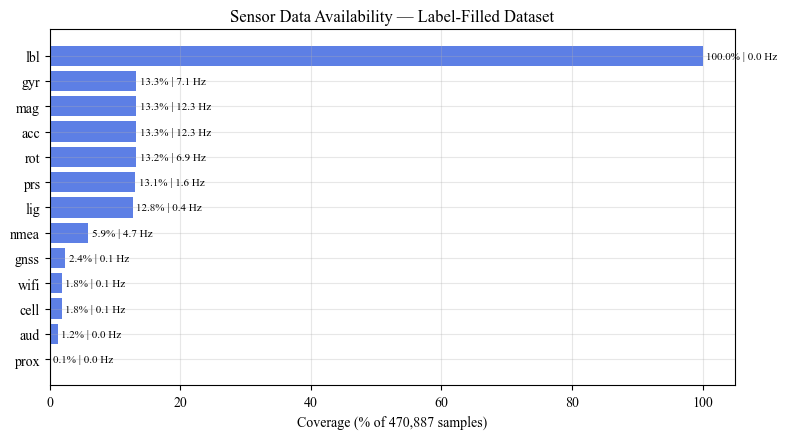

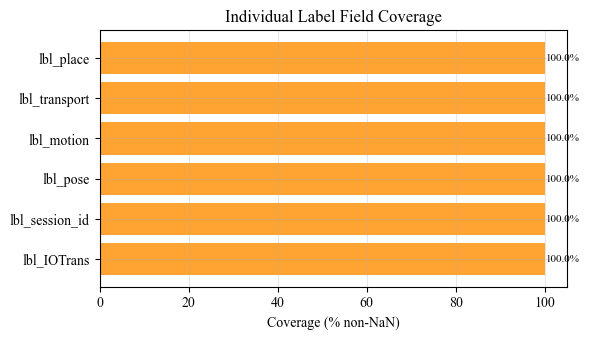

In [39]:
# ===============================================================
# 🧮 Sensor Coverage & Sampling Rate Analysis (with Label Breakdown)
# ===============================================================
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# -------------------------------------------------------------
# 1️⃣ Coverage by sensor prefix (based on fused timeline)
# -------------------------------------------------------------
prefixes = [
    "acc_", "gyr_", "mag_", "rot_", "prs_", "lig_", "prox_", "aud_",
    "wifi_", "cell_", "gnss_", "nmea_", "lbl_"
]

summary = []
total_rows = len(fused)

for pre in prefixes:
    cols = [c for c in fused.columns if c.startswith(pre)]
    if not cols:
        continue
    valid_rows = fused[cols].notna().any(axis=1).sum()
    coverage = 100 * valid_rows / total_rows
    summary.append({
        "Sensor": pre[:-1],
        "Columns": len(cols),
        "Valid Rows": valid_rows,
        "Coverage %": round(coverage, 2)
    })

summary_df = pd.DataFrame(summary).sort_values("Coverage %", ascending=False)
print(f"\n📊 Timeline coverage computed over {total_rows:,} fused samples.")

# -------------------------------------------------------------
# 2️⃣ Compute true sampling rates (based on merged raw CSVs)
# -------------------------------------------------------------
print("\n⚙️  Computing approximate sampling rates from merged raw data...")

def estimate_rate(df):
    if df is None or df.empty:
        return np.nan
    t = df["timestamp_ms"]
    if t.max() == t.min():
        return np.nan
    duration_s = (t.max() - t.min()) / 1000.0
    return len(t) / duration_s

raw_sources = {
    "acc": accel, "gyr": gyro, "mag": mag, "rot": rot,
    "prs": press, "lig": light, "prox": prox, "aud": audio,
    "wifi": wifi, "cell": cell, "gnss": gnss, "nmea": gnss_n, "lbl": labels
}

rates = []
for name, df in raw_sources.items():
    hz = estimate_rate(df)
    rates.append({"Sensor": name, "Sampling Rate (Hz)": round(hz, 2) if pd.notna(hz) else np.nan})

rates_df = pd.DataFrame(rates)

# Merge coverage + rate summaries
summary_df = pd.merge(summary_df, rates_df, on="Sensor", how="left")
summary_df = summary_df[["Sensor", "Columns", "Sampling Rate (Hz)", "Coverage %", "Valid Rows"]]
display(summary_df.style.background_gradient(cmap="YlGnBu", subset=["Coverage %"]))

# -------------------------------------------------------------
# 3️⃣ Per-label category coverage (inside lbl_ group)
# -------------------------------------------------------------
lbl_cols = [c for c in fused.columns if c.startswith("lbl_")]
if lbl_cols:
    lbl_cov = {c: fused[c].notna().mean() * 100 for c in lbl_cols}
    print("\n🧭 Individual Label Coverage (% non-NaN):")
    for k, v in lbl_cov.items():
        print(f"  {k:20s}: {v:5.1f}%")
    lbl_df = pd.DataFrame(list(lbl_cov.items()), columns=["Label Column", "Coverage %"])
    lbl_df = lbl_df.sort_values("Coverage %", ascending=False)
else:
    print("\n⚠ No lbl_* columns found — skipping label coverage plot.")
    lbl_df = pd.DataFrame(columns=["Label Column", "Coverage %"])

# -------------------------------------------------------------
# 4️⃣ Coverage bar plot (sensor prefixes)
# -------------------------------------------------------------
plt.figure(figsize=(8, 4.5))
bars = plt.barh(summary_df["Sensor"], summary_df["Coverage %"], color="royalblue", alpha=0.85)
plt.xlabel(f"Coverage (% of {total_rows:,} samples)")
plt.title("Sensor Data Availability — Label-Filled Dataset")
plt.gca().invert_yaxis()
plt.grid(alpha=0.3)

# Annotate coverage + sampling rate
for bar, (val, hz) in zip(bars, zip(summary_df["Coverage %"], summary_df["Sampling Rate (Hz)"])):
    txt = f"{val:.1f}%"
    if not np.isnan(hz):
        txt += f" | {hz:.1f} Hz"
    plt.text(val + 0.5, bar.get_y() + bar.get_height()/2, txt,
             va="center", fontsize=8)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 5️⃣ Optional: Label coverage plot (per label column)
# -------------------------------------------------------------
if not lbl_df.empty:
    plt.figure(figsize=(6, 3.5))
    bars = plt.barh(lbl_df["Label Column"], lbl_df["Coverage %"], color="darkorange", alpha=0.8)
    plt.xlabel("Coverage (% non-NaN)")
    plt.title("Individual Label Field Coverage")
    plt.gca().invert_yaxis()
    plt.grid(alpha=0.3)
    for bar, val in zip(bars, lbl_df["Coverage %"]):
        plt.text(val + 0.3, bar.get_y() + bar.get_height()/2,
                 f"{val:.1f}%", va="center", fontsize=8)
    plt.tight_layout()
    plt.show()


In [42]:
import pandas as pd

fused = pd.read_csv(r"D:\IOD\Runs\MergedSessions\fused_dataset.csv", low_memory=False)
fused.rename(columns=lambda c: c.replace("nmea_nmea_", "nmea_"), inplace=True)
fused.to_csv(r"D:\IOD\Runs\MergedSessions\fused_dataset.csv", index=False)
print("✅ Fixed:", [c for c in fused.columns if c.startswith("nmea_")])


✅ Fixed: ['nmea_sats_in_view', 'nmea_sats_used', 'nmea_vdop', 'nmea_pdop', 'nmea_hdop', 'nmea_mean_cn0', 'nmea_alt_m']


🛰 Found 4 GNSS session(s): ['session_1' 'session_2' 'session_3' 'session_4']


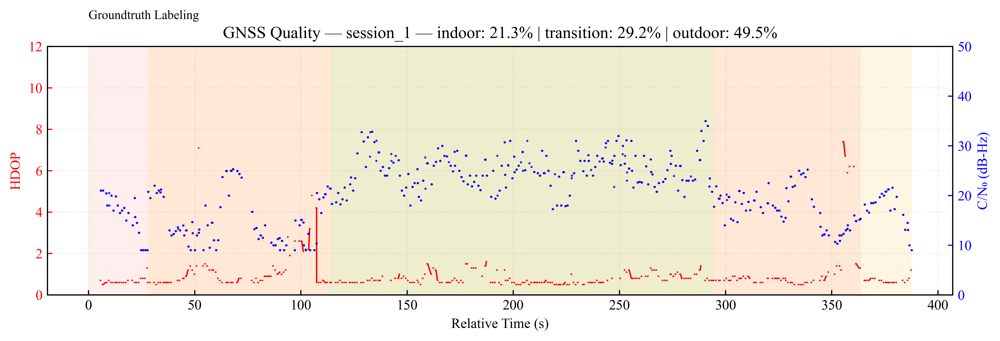

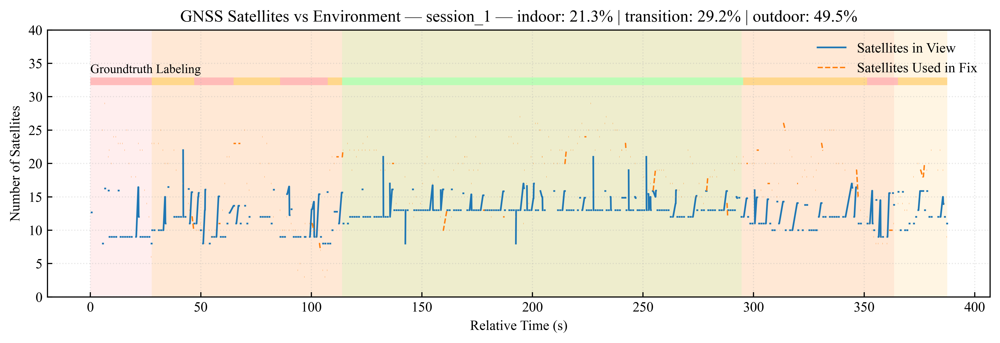

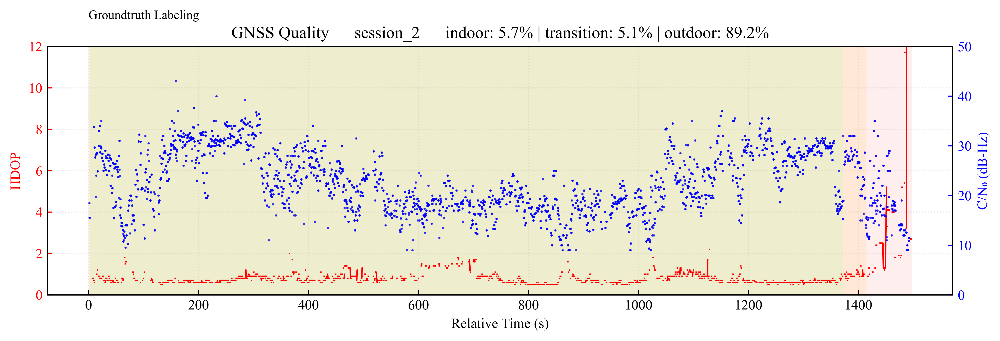

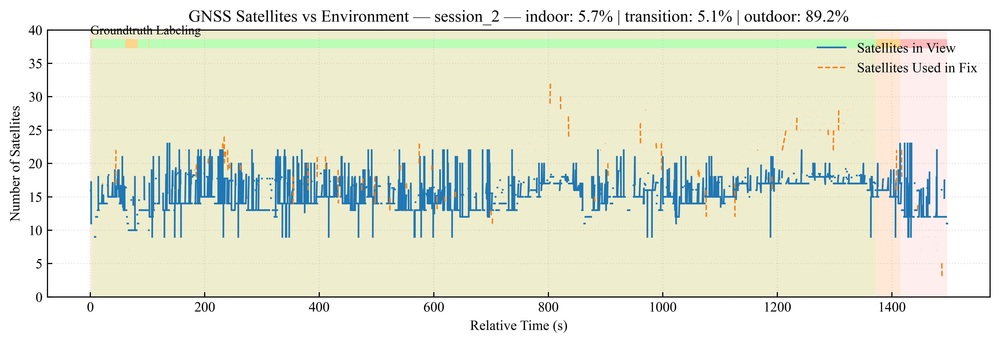

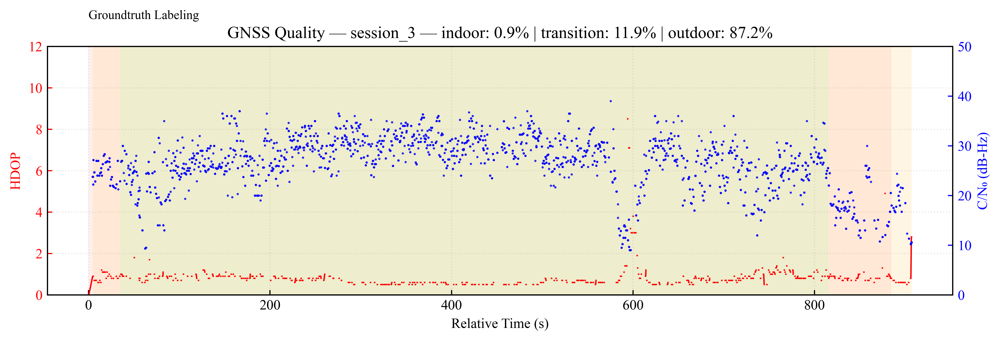

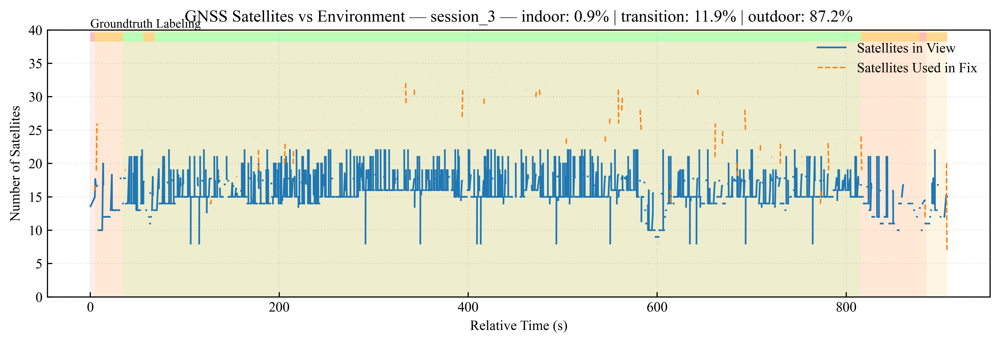

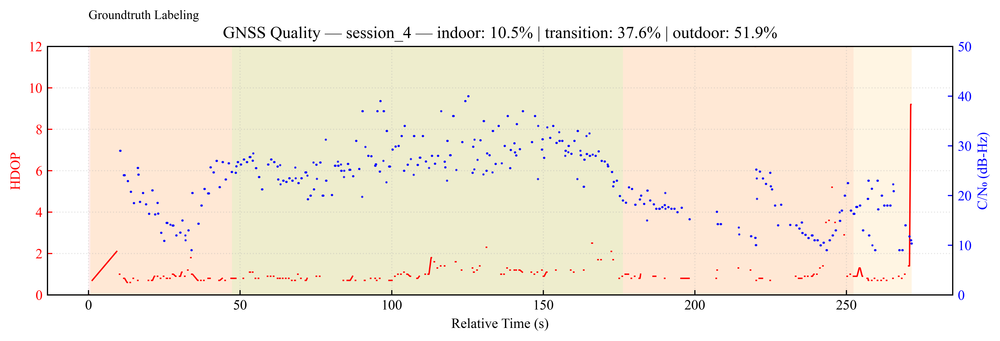

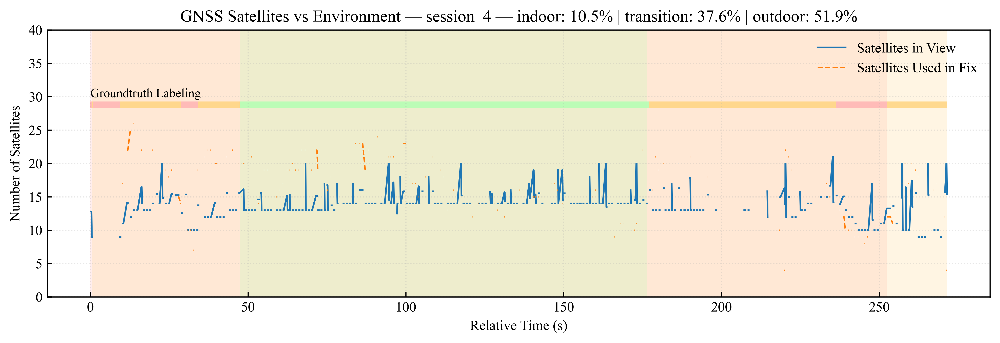

In [43]:
# ===============================================================
# 📈 GNSS Quality vs Environment — Per-Session (HDOP, CN0, Sats)
# ===============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from matplotlib import rcParams

# ---------------------------------------------------------------
# Style setup
# ---------------------------------------------------------------
rcParams["font.family"] = "serif"
rcParams["font.serif"] = ["Times New Roman"]
rcParams["mathtext.default"] = "regular"

# ---------------------------------------------------------------
# Environment color map
# ---------------------------------------------------------------
env_colors = {
    "indoor": "#ffb3b3",      # red
    "transition": "#ffd480",  # orange
    "outdoor": "#b3ffb3"      # green
}

# ---------------------------------------------------------------
# Helper to draw environment bar
# ---------------------------------------------------------------
def draw_env_bar(ax, df, y, height=0.05, alpha=0.85):
    prev_env = df["lbl_IOTrans"].iloc[0]
    start_t = df["t_rel"].iloc[0]
    for i in range(1, len(df)):
        curr_env = df["lbl_IOTrans"].iloc[i]
        if curr_env != prev_env or i == len(df) - 1:
            end_t = df["t_rel"].iloc[i]
            color = env_colors.get(prev_env, "white")
            ax.add_patch(Rectangle(
                (start_t, y),
                end_t - start_t,
                height,
                color=color,
                alpha=alpha,
                lw=0
            ))
            prev_env = curr_env
            start_t = end_t

# ---------------------------------------------------------------
# Sanity checks
# ---------------------------------------------------------------
required_cols = [
    "nmea_hdop", "nmea_mean_cn0", "nmea_sats_in_view", "nmea_sats_used"
]
for col in required_cols:
    if col not in fused.columns:
        print(f"⚠ Missing {col} in fused dataset (some metrics may be skipped).")

if "gnss_session_id" not in fused.columns:
    raise KeyError("⚠ Missing gnss_session_id in dataset.")
if "lbl_IOTrans" not in fused.columns:
    raise KeyError("⚠ Missing lbl_IOTrans (environment labels).")

# ---------------------------------------------------------------
# Process each session
# ---------------------------------------------------------------
sessions = fused["gnss_session_id"].dropna().unique()
print(f"🛰 Found {len(sessions)} GNSS session(s): {sessions}")

# Fixed axis limits for comparability
HDOP_YLIM = (0, 12)
CNO_YLIM  = (0, 50)
SATS_YLIM = (0, 40)

for sid in sessions:
    df_s = fused[fused["gnss_session_id"] == sid].copy().sort_values("timestamp_ms").reset_index(drop=True)

    if df_s[["nmea_hdop", "nmea_mean_cn0"]].notna().sum().sum() < 10:
        print(f"⚠ Skipping {sid}: insufficient GNSS data.")
        continue

    # --- Handle timestamp gaps properly ---
    df_s["t_diff"] = df_s["timestamp_ms"].diff().fillna(0)
    df_s["segment_id"] = (df_s["t_diff"] > 10000).cumsum()
    df_s["t_rel"] = df_s.groupby("segment_id")["timestamp_ms"].transform(lambda x: (x - x.min()) / 1000.0)
    seg_offsets = df_s.groupby("segment_id")["t_rel"].max().cumsum().shift(fill_value=0)
    df_s["t_rel"] += df_s["segment_id"].map(seg_offsets)

    # --- Environment proportions for title ---
    env_counts = df_s["lbl_IOTrans"].value_counts(normalize=True) * 100
    env_legend = " | ".join([
        f"{k}: {env_counts.get(k, 0):.1f}%" for k in ["indoor", "transition", "outdoor"]
    ])

    # -----------------------------------------------------------
    # Plot — HDOP & CN0 on first figure
    # -----------------------------------------------------------
    fig, ax1 = plt.subplots(figsize=(10, 3.5), dpi=500)
    ax2 = ax1.twinx()

    # Continuous background shading
    for env, color in env_colors.items():
        mask = df_s["lbl_IOTrans"] == env
        if mask.any():
            ax1.axvspan(df_s.loc[mask, "t_rel"].min(),
                        df_s.loc[mask, "t_rel"].max(),
                        color=color, alpha=0.22, lw=0)

    # HDOP (red)
    if "nmea_hdop" in df_s:
        ax1.plot(df_s["t_rel"], df_s["nmea_hdop"].clip(*HDOP_YLIM),
                 "r-", lw=1.0, label="HDOP")
        ax1.set_ylabel("HDOP", color="red")
        ax1.set_ylim(*HDOP_YLIM)

    # CN0 (blue)
    if "nmea_mean_cn0" in df_s:
        ax2.plot(df_s["t_rel"], df_s["nmea_mean_cn0"].clip(*CNO_YLIM),
                 "b.", ms=1.2, alpha=0.8, label="C/N₀ (dB-Hz)")
        ax2.set_ylabel("C/N₀ (dB-Hz)", color="blue")
        ax2.set_ylim(*CNO_YLIM)

    # Top bar
    y_min, y_max = ax1.get_ylim()
    y_span = y_max - y_min
    bar_y = y_max + 0.05 * y_span
    draw_env_bar(ax1, df_s, bar_y, height=0.04 * y_span)
    ax1.text(df_s["t_rel"].min(), bar_y + 0.05 * y_span, "Groundtruth Labeling",
             fontsize=9, color="black", ha="left", va="bottom")

    # Formatting
    ax1.set_xlabel("Relative Time (s)")
    ax1.set_title(f"GNSS Quality — {sid} — {env_legend}")
    ax1.tick_params(axis="x", direction="in", colors="black")
    ax1.tick_params(axis="y", direction="in", colors="red")
    ax2.tick_params(axis="y", direction="in", colors="blue")
    ax1.grid(alpha=0.3, linestyle=":")
    plt.tight_layout()
    plt.show()

    # -----------------------------------------------------------
    # Plot — Satellites Used & In View
    # -----------------------------------------------------------
    if "nmea_sats_used" in df_s or "nmea_sats_in_view" in df_s:
        fig, ax = plt.subplots(figsize=(10, 3.5), dpi=500)

        # Background shading
        for env, color in env_colors.items():
            mask = df_s["lbl_IOTrans"] == env
            if mask.any():
                ax.axvspan(df_s.loc[mask, "t_rel"].min(),
                           df_s.loc[mask, "t_rel"].max(),
                           color=color, alpha=0.22, lw=0)

        # Total satellites in view (blue)
        if "nmea_sats_in_view" in df_s:
            ax.plot(df_s["t_rel"], df_s["nmea_sats_in_view"].clip(*SATS_YLIM),
                    color="tab:blue", lw=1.2, label="Satellites in View")

        # Satellites used in fix (orange dashed)
        if "nmea_sats_used" in df_s:
            ax.plot(df_s["t_rel"], df_s["nmea_sats_used"].clip(*SATS_YLIM),
                    color="tab:orange", lw=1.0, linestyle="--", label="Satellites Used in Fix")

        # Top bar
        y_min, y_max = ax.get_ylim()
        y_span = y_max - y_min
        bar_y = y_max + 0.05 * y_span
        draw_env_bar(ax, df_s, bar_y, height=0.04 * y_span)
        ax.text(df_s["t_rel"].min(), bar_y + 0.05 * y_span, "Groundtruth Labeling",
                fontsize=9, color="black", ha="left", va="bottom")

        # Formatting
        ax.set_ylim(*SATS_YLIM)
        ax.set_xlabel("Relative Time (s)")
        ax.set_ylabel("Number of Satellites")
        ax.set_title(f"GNSS Satellites vs Environment — {sid} — {env_legend}")
        ax.tick_params(axis="x", direction="in", colors="black")
        ax.tick_params(axis="y", direction="in", colors="black")
        ax.grid(alpha=0.3, linestyle=":")
        ax.legend(loc="upper right", frameon=False)
        plt.tight_layout()
        plt.show()


🛰 Found 4 GNSS session(s): ['session_1' 'session_2' 'session_3' 'session_4']


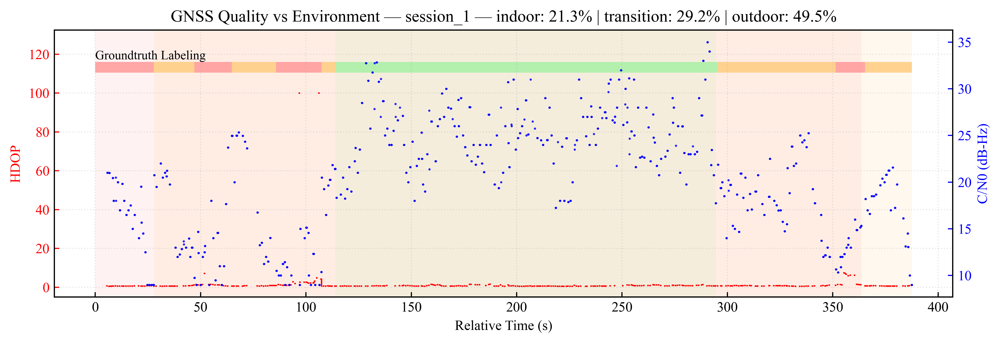

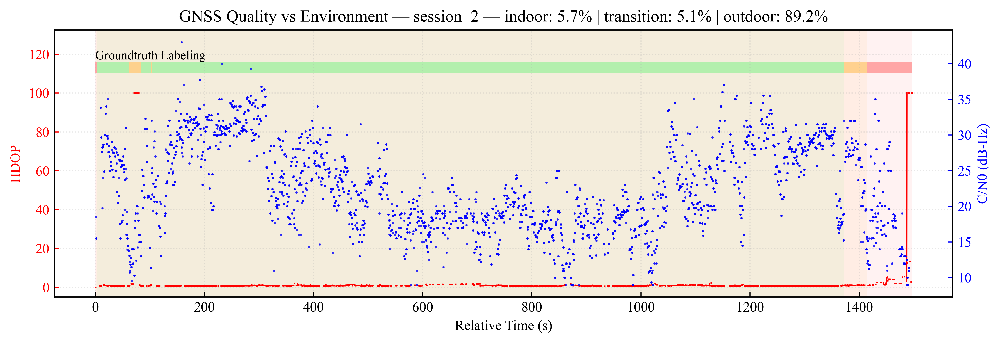

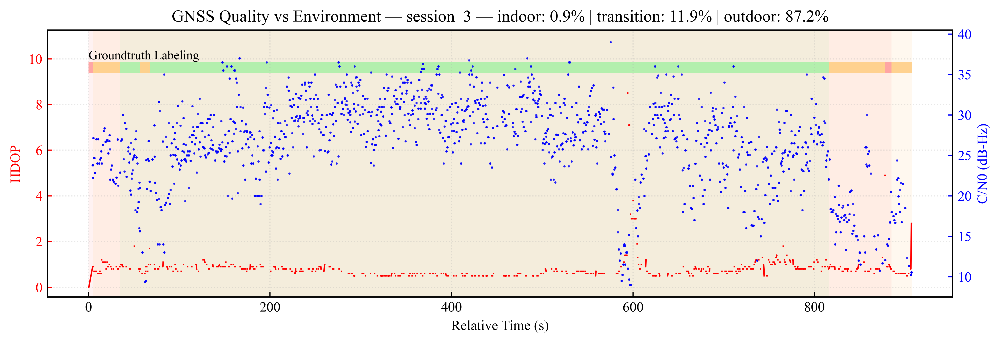

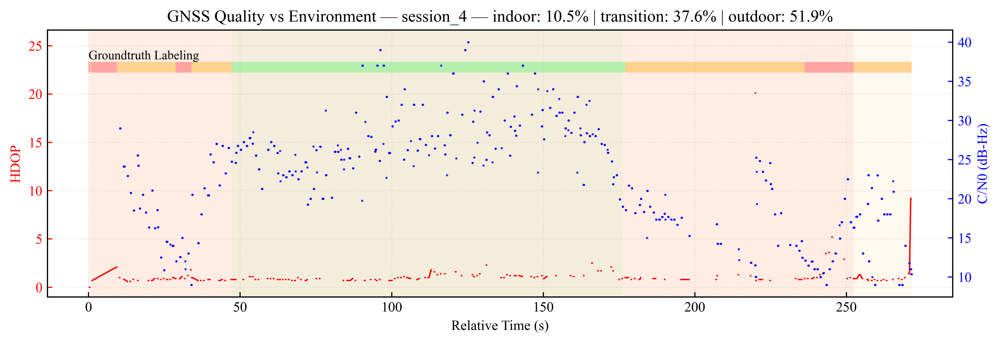

In [44]:
# ===============================================================
# 📈 GNSS Quality vs Environment — Per-Session (Correct t_rel)
# ===============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from matplotlib import rcParams

# ---------------------------------------------------------------
# Style setup
# ---------------------------------------------------------------
rcParams["font.family"] = "serif"
rcParams["font.serif"] = ["Times New Roman"]
rcParams["mathtext.default"] = "regular"

# ---------------------------------------------------------------
# Environment color map
# ---------------------------------------------------------------
env_colors = {
    "indoor": "#ff9999",      # red
    "transition": "#ffcc80",  # orange
    "outdoor": "#a8f0a5"      # green
}

# ---------------------------------------------------------------
# Helper to draw environment bar
# ---------------------------------------------------------------
def draw_env_bar(ax, df, y, height=0.05, alpha=0.85):
    prev_env = df["lbl_IOTrans"].iloc[0]
    start_t = df["t_rel"].iloc[0]
    for i in range(1, len(df)):
        curr_env = df["lbl_IOTrans"].iloc[i]
        if curr_env != prev_env or i == len(df) - 1:
            end_t = df["t_rel"].iloc[i]
            color = env_colors.get(prev_env, "white")
            ax.add_patch(Rectangle(
                (start_t, y),
                end_t - start_t,
                height,
                color=color,
                alpha=alpha,
                lw=0
            ))
            prev_env = curr_env
            start_t = end_t

# ---------------------------------------------------------------
# Sanity check
# ---------------------------------------------------------------
if "gnss_session_id" not in fused.columns:
    raise KeyError("⚠ Missing gnss_session_id in dataset.")
if "lbl_IOTrans" not in fused.columns:
    raise KeyError("⚠ Missing lbl_IOTrans (environment labels).")

gnss_cols = [c for c in ["nmea_hdop", "nmea_mean_cn0"] if c in fused.columns]
if not gnss_cols:
    raise RuntimeError("⚠ No GNSS quality columns found (need nmea_hdop / nmea_mean_cn0).")

# ---------------------------------------------------------------
# Process each session
# ---------------------------------------------------------------
sessions = fused["gnss_session_id"].dropna().unique()
print(f"🛰 Found {len(sessions)} GNSS session(s): {sessions}")

for sid in sessions:
    df_s = fused[fused["gnss_session_id"] == sid].copy().sort_values("timestamp_ms").reset_index(drop=True)
    if df_s[gnss_cols].notna().sum().sum() < 10:
        print(f"⚠ Skipping {sid}: insufficient GNSS data.")
        continue

    # --- Handle timestamp gaps properly ---
    df_s["t_diff"] = df_s["timestamp_ms"].diff().fillna(0)
    # new segment if time gap > 10 s
    df_s["segment_id"] = (df_s["t_diff"] > 10000).cumsum()

    # compute relative time within each contiguous block
    df_s["t_rel"] = df_s.groupby("segment_id")["timestamp_ms"].transform(lambda x: (x - x.min()) / 1000.0)

    # shift each new block so time continues naturally
    seg_offsets = df_s.groupby("segment_id")["t_rel"].max().cumsum().shift(fill_value=0)
    df_s["t_rel"] += df_s["segment_id"].map(seg_offsets)

    # --- Environment proportions for title ---
    env_counts = df_s["lbl_IOTrans"].value_counts(normalize=True) * 100
    env_legend = " | ".join([
        f"{k}: {env_counts.get(k, 0):.1f}%" for k in ["indoor", "transition", "outdoor"]
    ])

    # -----------------------------------------------------------
    # Plot
    # -----------------------------------------------------------
    fig, ax1 = plt.subplots(figsize=(10, 3.5), dpi=500)
    ax2 = ax1.twinx()

    # Background shading
    for env, color in env_colors.items():
        mask = df_s["lbl_IOTrans"] == env
        if mask.any():
            ax1.axvspan(
                df_s.loc[mask, "t_rel"].min(),
                df_s.loc[mask, "t_rel"].max(),
                color=color,
                alpha=0.12,
                lw=0
            )

    # GNSS metrics
    if "nmea_hdop" in df_s:
        ax1.plot(df_s["t_rel"], df_s["nmea_hdop"], "r-", lw=1.0, label="HDOP")
        ax1.set_ylabel("HDOP", color="red")
    if "nmea_mean_cn0" in df_s:
        ax2.plot(df_s["t_rel"], df_s["nmea_mean_cn0"], "b.", ms=1.2, alpha=0.8, label="C/N0 (dB-Hz)")
        ax2.set_ylabel("C/N0 (dB-Hz)", color="blue")

    # Top groundtruth bar
    y_min, y_max = ax1.get_ylim()
    y_span = y_max - y_min
    ax1.set_ylim(y_min, y_max + 0.25 * y_span)
    bar_y = y_max + 0.05 * y_span
    draw_env_bar(ax1, df_s, bar_y, height=0.05 * y_span)
    ax1.text(df_s["t_rel"].min(), bar_y + 0.05 * y_span,
             "Groundtruth Labeling", fontsize=9, color="black", ha="left", va="bottom")

    # Formatting
    ax1.set_xlabel("Relative Time (s)")
    ax1.set_title(f"GNSS Quality vs Environment — {sid} — {env_legend}")
    ax1.tick_params(axis="x", direction="in", colors="black")
    ax1.tick_params(axis="y", direction="in", colors="red")
    ax2.tick_params(axis="y", direction="in", colors="blue")
    ax1.yaxis.label.set_color("red")
    ax2.yaxis.label.set_color("blue")
    ax1.grid(alpha=0.3, linestyle=":")
    plt.tight_layout()
    plt.show()


🛰 Found 4 GNSS session(s): ['session_1' 'session_2' 'session_3' 'session_4']


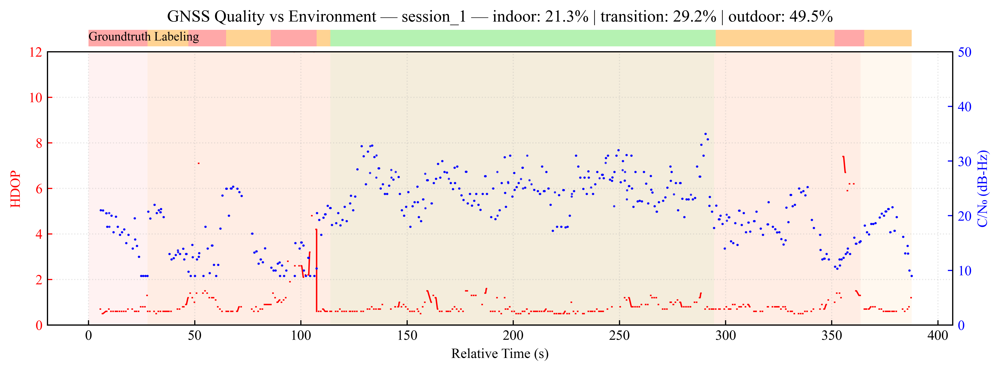

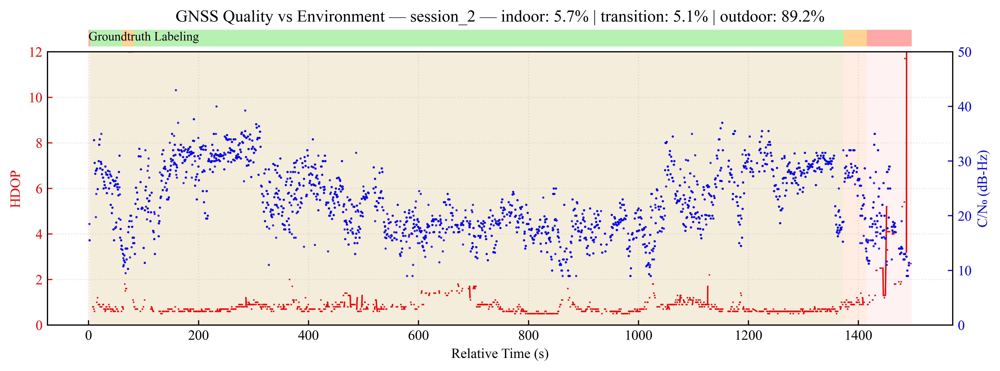

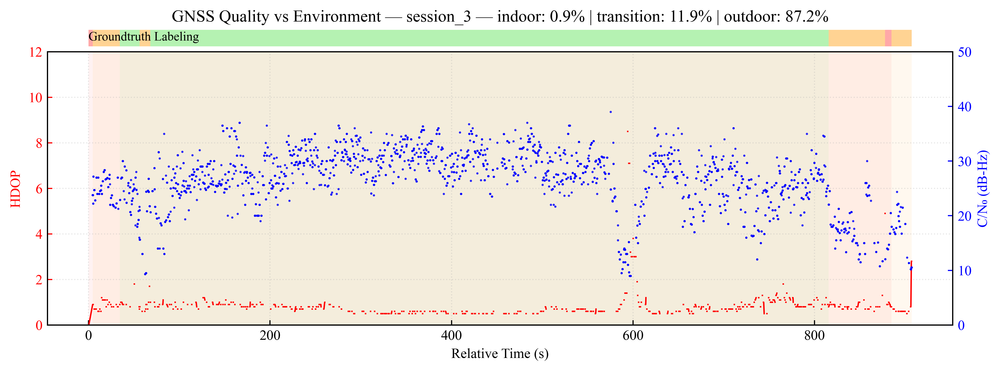

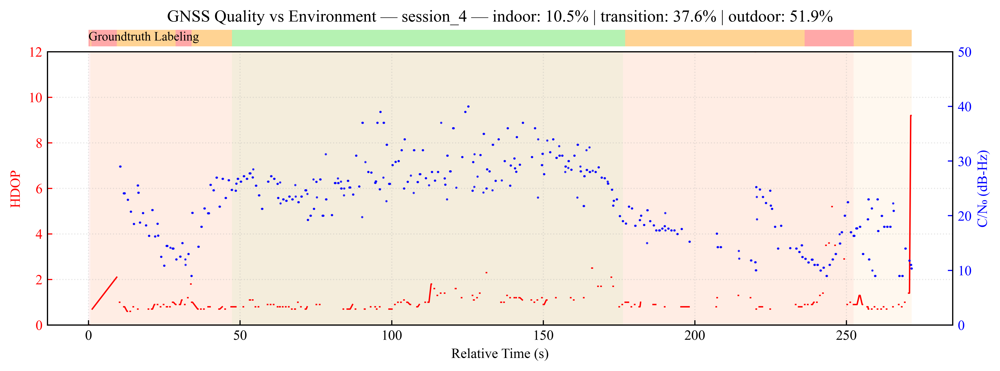

In [45]:
# ===============================================================
# 📈 GNSS Quality vs Environment — Per-Session (Uniform Scales + Bar)
# ===============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from matplotlib import rcParams

# ---------------------------------------------------------------
# Style
# ---------------------------------------------------------------
rcParams["font.family"] = "serif"
rcParams["font.serif"] = ["Times New Roman"]
rcParams["mathtext.default"] = "regular"

# ---------------------------------------------------------------
# Environment colors
# ---------------------------------------------------------------
env_colors = {
    "indoor": "#ff9999",      # red
    "transition": "#ffcc80",  # orange
    "outdoor": "#a8f0a5"      # green
}

# ---------------------------------------------------------------
# Helper: draw environment bar
# ---------------------------------------------------------------
def draw_env_bar(ax, df, height=0.4, alpha=0.85):
    """Draw horizontal colored bar along the top axis."""
    prev_env = df["lbl_IOTrans"].iloc[0]
    start_t = df["t_rel"].iloc[0]
    for i in range(1, len(df)):
        curr_env = df["lbl_IOTrans"].iloc[i]
        if curr_env != prev_env or i == len(df) - 1:
            end_t = df["t_rel"].iloc[i]
            color = env_colors.get(prev_env, "white")
            ax.add_patch(Rectangle(
                (start_t, 0),
                end_t - start_t,
                height,
                color=color,
                alpha=alpha,
                lw=0
            ))
            prev_env = curr_env
            start_t = end_t

# ---------------------------------------------------------------
# Axis limits
# ---------------------------------------------------------------
HDOP_YLIM = (0, 12)
CNO_YLIM  = (0, 50)

# ---------------------------------------------------------------
# Checks
# ---------------------------------------------------------------
if "gnss_session_id" not in fused.columns:
    raise KeyError("⚠ Missing gnss_session_id column.")
if "lbl_IOTrans" not in fused.columns:
    raise KeyError("⚠ Missing lbl_IOTrans column.")
gnss_cols = [c for c in ["nmea_hdop", "nmea_mean_cn0"] if c in fused.columns]
if not gnss_cols:
    raise RuntimeError("⚠ Need at least one GNSS metric (nmea_hdop or nmea_mean_cn0).")

# ---------------------------------------------------------------
# Loop over sessions
# ---------------------------------------------------------------
sessions = fused["gnss_session_id"].dropna().unique()
print(f"🛰 Found {len(sessions)} GNSS session(s): {sessions}")

for sid in sessions:
    df_s = fused[fused["gnss_session_id"] == sid].copy().sort_values("timestamp_ms").reset_index(drop=True)
    if df_s[gnss_cols].notna().sum().sum() < 10:
        print(f"⚠ Skipping {sid}: insufficient GNSS data.")
        continue

    # Relative time per contiguous block
    df_s["t_diff"] = df_s["timestamp_ms"].diff().fillna(0)
    df_s["segment_id"] = (df_s["t_diff"] > 10000).cumsum()
    df_s["t_rel"] = df_s.groupby("segment_id")["timestamp_ms"].transform(lambda x: (x - x.min()) / 1000.0)
    seg_offsets = df_s.groupby("segment_id")["t_rel"].max().cumsum().shift(fill_value=0)
    df_s["t_rel"] += df_s["segment_id"].map(seg_offsets)

    # Environment proportions
    env_counts = df_s["lbl_IOTrans"].value_counts(normalize=True) * 100
    env_legend = " | ".join([
        f"{k}: {env_counts.get(k, 0):.1f}%" for k in ["indoor", "transition", "outdoor"]
    ])

    # -----------------------------------------------------------
    # Plot main GNSS metrics
    # -----------------------------------------------------------
    fig, ax1 = plt.subplots(figsize=(10, 3.8), dpi=500)
    ax2 = ax1.twinx()

    # Shaded background
    for env, color in env_colors.items():
        mask = df_s["lbl_IOTrans"] == env
        if mask.any():
            ax1.axvspan(df_s.loc[mask, "t_rel"].min(),
                        df_s.loc[mask, "t_rel"].max(),
                        color=color, alpha=0.12, lw=0)

    # HDOP
    if "nmea_hdop" in df_s:
        ax1.plot(df_s["t_rel"], df_s["nmea_hdop"].clip(*HDOP_YLIM),
                 "r-", lw=1.0)
        ax1.set_ylabel("HDOP", color="red")
        ax1.set_ylim(*HDOP_YLIM)

    # C/N0
    if "nmea_mean_cn0" in df_s:
        ax2.plot(df_s["t_rel"], df_s["nmea_mean_cn0"].clip(*CNO_YLIM),
                 "b.", ms=1.2, alpha=0.8)
        ax2.set_ylabel("C/N₀ (dB-Hz)", color="blue")
        ax2.set_ylim(*CNO_YLIM)

    # -----------------------------------------------------------
    # Add a separate top bar axis (always visible)
    # -----------------------------------------------------------
    bar_ax = ax1.inset_axes([0, 1.02, 1, 0.06], sharex=ax1)  # x-aligned small axis
    draw_env_bar(bar_ax, df_s, height=1)
    bar_ax.set_xlim(ax1.get_xlim())
    bar_ax.set_ylim(0, 1)
    bar_ax.axis("off")
    bar_ax.text(df_s["t_rel"].min(), 0.55, "Groundtruth Labeling",
                fontsize=9, color="black", ha="left", va="center")

    # -----------------------------------------------------------
    # Formatting
    # -----------------------------------------------------------
    ax1.set_xlabel("Relative Time (s)")
    ax1.set_title(f"GNSS Quality vs Environment — {sid} — {env_legend}")
    ax1.tick_params(axis="x", direction="in", colors="black")
    ax1.tick_params(axis="y", direction="in", colors="red")
    ax2.tick_params(axis="y", direction="in", colors="blue")
    ax1.yaxis.label.set_color("red")
    ax2.yaxis.label.set_color("blue")
    ax1.grid(alpha=0.3, linestyle=":")
    plt.tight_layout()
    plt.show()


🛰 Found 4 GNSS session(s): ['session_1' 'session_2' 'session_3' 'session_4']


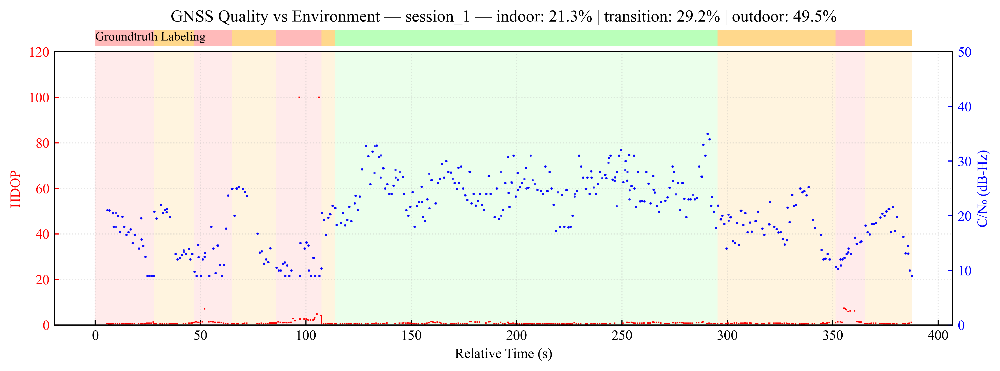

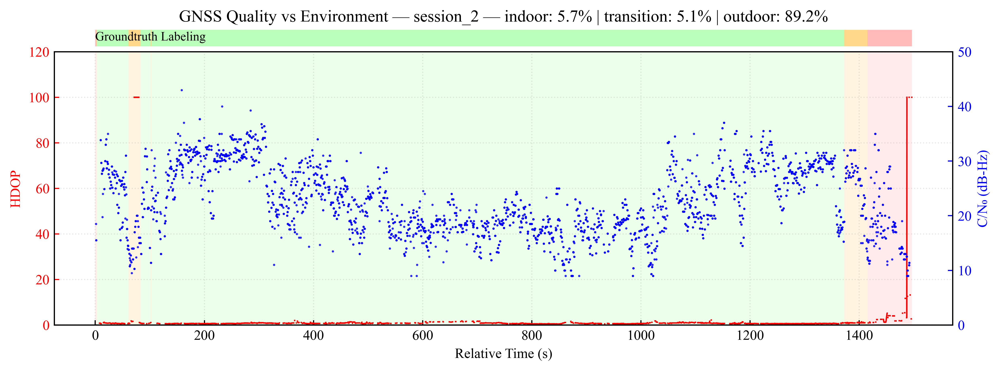

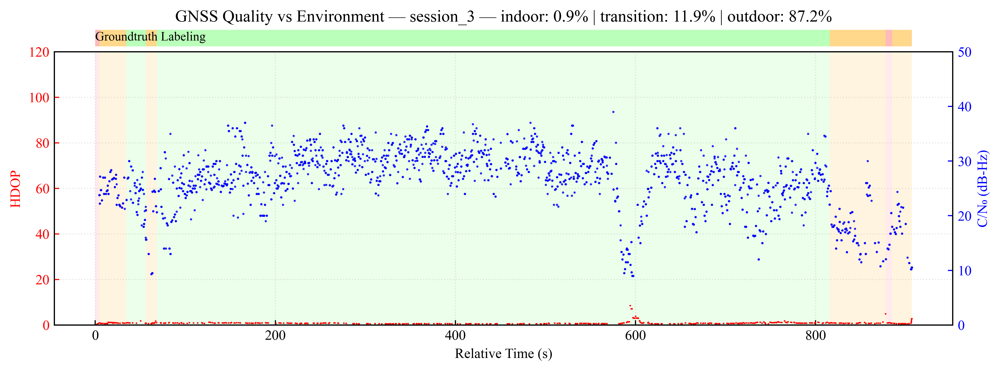

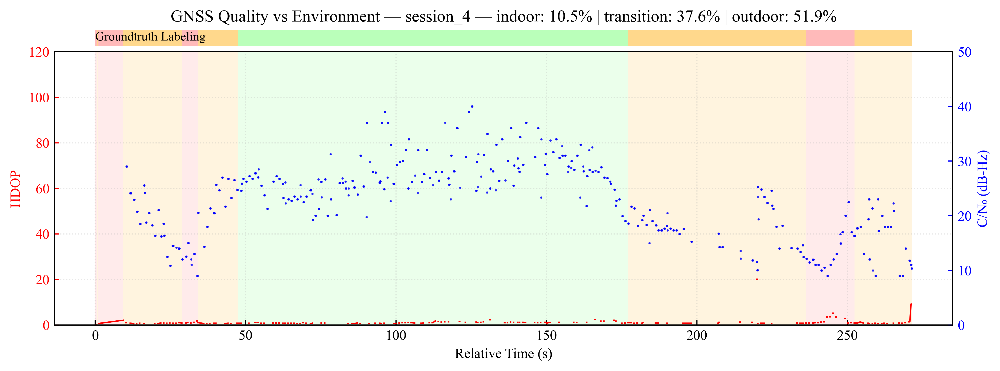

In [62]:
# ===============================================================
# 📈 GNSS Quality vs Environment — Per-Session
#      (Uniform Scales + Continuous Background + Top Bar)
# ===============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from matplotlib import rcParams

# ---------------------------------------------------------------
# Style setup
# ---------------------------------------------------------------
rcParams["font.family"] = "serif"
rcParams["font.serif"] = ["Times New Roman"]
rcParams["mathtext.default"] = "regular"

# ---------------------------------------------------------------
# Environment color map (consistent indoor→transition→outdoor)
# ---------------------------------------------------------------
env_colors = {
    "indoor": "#ffb3b3",       # soft red
    "transition": "#ffd480",   # soft orange
    "outdoor": "#b3ffb3"       # soft green
}

# ---------------------------------------------------------------
# Helper to draw top environment bar
# ---------------------------------------------------------------
def draw_env_bar(ax, df, height=1.0, alpha=0.9):
    """Draw horizontal colored bar on a small top inset axis."""
    prev_env = df["lbl_IOTrans"].iloc[0]
    start_t = df["t_rel"].iloc[0]
    for i in range(1, len(df)):
        curr_env = df["lbl_IOTrans"].iloc[i]
        if curr_env != prev_env or i == len(df) - 1:
            end_t = df["t_rel"].iloc[i]
            color = env_colors.get(prev_env, "white")
            ax.add_patch(Rectangle((start_t, 0), end_t - start_t, height,
                                   color=color, alpha=alpha, lw=0))
            prev_env = curr_env
            start_t = end_t

# ---------------------------------------------------------------
# Fixed axis limits
# ---------------------------------------------------------------
HDOP_YLIM = (0, 120)
CNO_YLIM  = (0, 50)

# ---------------------------------------------------------------
# Sanity checks
# ---------------------------------------------------------------
if "gnss_session_id" not in fused.columns:
    raise KeyError("⚠ Missing gnss_session_id column.")
if "lbl_IOTrans" not in fused.columns:
    raise KeyError("⚠ Missing lbl_IOTrans column.")
gnss_cols = [c for c in ["nmea_hdop", "nmea_mean_cn0"] if c in fused.columns]
if not gnss_cols:
    raise RuntimeError("⚠ Need at least one GNSS metric (nmea_hdop or nmea_mean_cn0).")

# ---------------------------------------------------------------
# Loop over sessions
# ---------------------------------------------------------------
sessions = fused["gnss_session_id"].dropna().unique()
print(f"🛰 Found {len(sessions)} GNSS session(s): {sessions}")

for sid in sessions:
    df_s = fused[fused["gnss_session_id"] == sid].copy().sort_values("timestamp_ms").reset_index(drop=True)
    if df_s[gnss_cols].notna().sum().sum() < 10:
        print(f"⚠ Skipping {sid}: insufficient GNSS data.")
        continue

    # Relative time with gap correction
    df_s["t_diff"] = df_s["timestamp_ms"].diff().fillna(0)
    df_s["segment_id"] = (df_s["t_diff"] > 10000).cumsum()
    df_s["t_rel"] = df_s.groupby("segment_id")["timestamp_ms"].transform(lambda x: (x - x.min()) / 1000.0)
    seg_offsets = df_s.groupby("segment_id")["t_rel"].max().cumsum().shift(fill_value=0)
    df_s["t_rel"] += df_s["segment_id"].map(seg_offsets)

    # Environment proportions
    env_counts = df_s["lbl_IOTrans"].value_counts(normalize=True) * 100
    env_legend = " | ".join([f"{k}: {env_counts.get(k, 0):.1f}%" for k in ["indoor", "transition", "outdoor"]])

    # -----------------------------------------------------------
    # Plot main figure
    # -----------------------------------------------------------
    fig, ax1 = plt.subplots(figsize=(10, 3.8), dpi=500)
    ax2 = ax1.twinx()

    # --- Continuous colored background by environment ---
    prev_env = df_s["lbl_IOTrans"].iloc[0]
    start_t = df_s["t_rel"].iloc[0]
    for i in range(1, len(df_s)):
        curr_env = df_s["lbl_IOTrans"].iloc[i]
        if curr_env != prev_env or i == len(df_s) - 1:
            end_t = df_s["t_rel"].iloc[i]
            color = env_colors.get(prev_env, "white")
            ax1.axvspan(start_t, end_t, facecolor=color, alpha=0.25, lw=0)
            prev_env = curr_env
            start_t = end_t

    # --- GNSS metrics ---
    if "nmea_hdop" in df_s:
        ax1.plot(df_s["t_rel"], df_s["nmea_hdop"].clip(*HDOP_YLIM),
                 "r-", lw=1.0)
        ax1.set_ylabel("HDOP", color="red")
        ax1.set_ylim(*HDOP_YLIM)
    if "nmea_mean_cn0" in df_s:
        ax2.plot(df_s["t_rel"], df_s["nmea_mean_cn0"].clip(*CNO_YLIM),
                 "b.", ms=1.2, alpha=0.8)
        ax2.set_ylabel("C/N₀ (dB-Hz)", color="blue")
        ax2.set_ylim(*CNO_YLIM)

    # --- Top bar inset (always visible) ---
    bar_ax = ax1.inset_axes([0, 1.02, 1, 0.06], sharex=ax1)
    draw_env_bar(bar_ax, df_s)
    bar_ax.set_xlim(ax1.get_xlim())
    bar_ax.set_ylim(0, 1)
    bar_ax.axis("off")
    bar_ax.text(df_s["t_rel"].min(), 0.55, "Groundtruth Labeling",
                fontsize=9, color="black", ha="left", va="center")

    # --- Formatting ---
    ax1.set_xlabel("Relative Time (s)")
    ax1.set_title(f"GNSS Quality vs Environment — {sid} — {env_legend}")
    ax1.tick_params(axis="x", direction="in", colors="black")
    ax1.tick_params(axis="y", direction="in", colors="red")
    ax2.tick_params(axis="y", direction="in", colors="blue")
    ax1.yaxis.label.set_color("red")
    ax2.yaxis.label.set_color("blue")
    ax1.grid(alpha=0.3, linestyle=":")
    plt.tight_layout()
    plt.show()


🛰 Found 4 GNSS session(s): ['session_1' 'session_2' 'session_3' 'session_4']


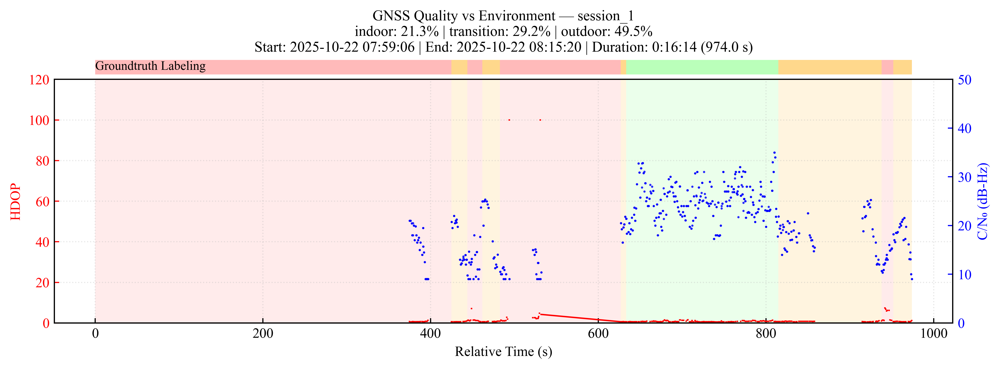

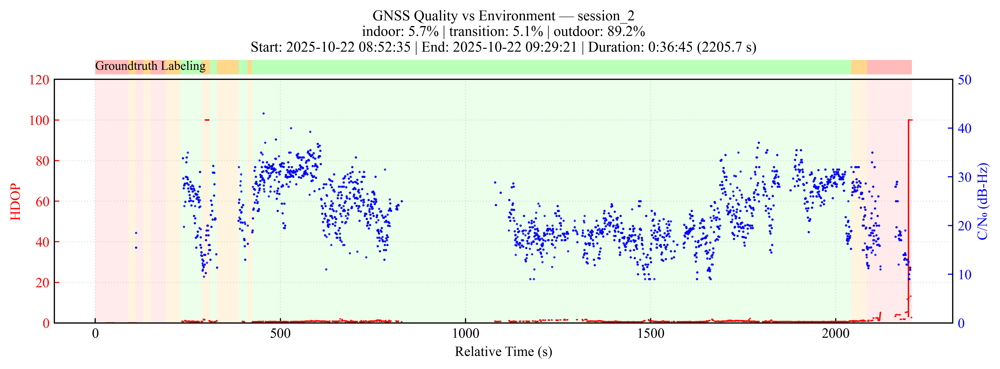

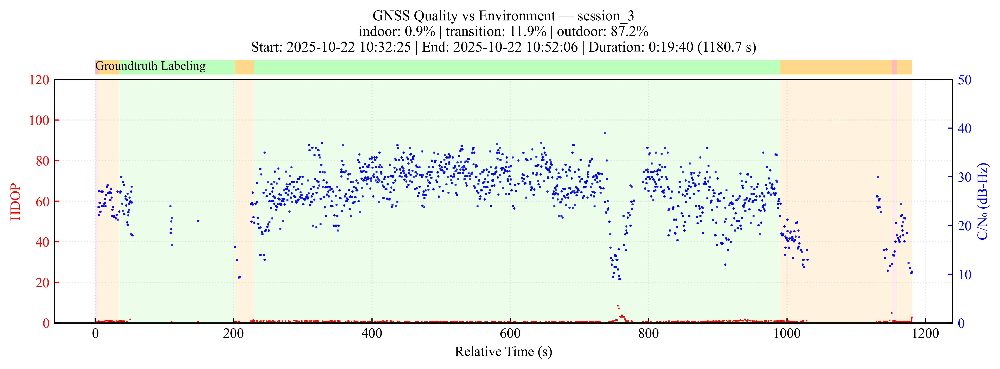

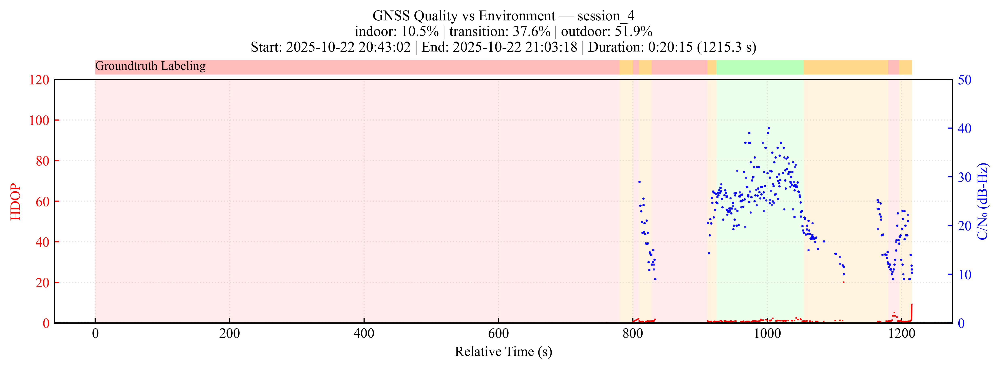

In [69]:
# ===============================================================
# 📈 GNSS Quality vs Environment — Per-Session
#   (Real Continuous Time on X-axis — True Duration)
# ===============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from matplotlib import rcParams
from datetime import datetime, timedelta

# ---------------------------------------------------------------
# Style setup
# ---------------------------------------------------------------
rcParams["font.family"] = "serif"
rcParams["font.serif"] = ["Times New Roman"]
rcParams["mathtext.default"] = "regular"

# ---------------------------------------------------------------
# Environment color map
# ---------------------------------------------------------------
env_colors = {
    "indoor": "#ffb3b3",       # soft red
    "transition": "#ffd480",   # soft orange
    "outdoor": "#b3ffb3"       # soft green
}

# ---------------------------------------------------------------
# Helper: draw top environment bar
# ---------------------------------------------------------------
def draw_env_bar(ax, df, height=1.0, alpha=0.9):
    """Draw colored segments for environment changes."""
    prev_env = df["lbl_IOTrans"].iloc[0]
    start_t = df["t_rel"].iloc[0]
    for i in range(1, len(df)):
        curr_env = df["lbl_IOTrans"].iloc[i]
        if curr_env != prev_env or i == len(df) - 1:
            end_t = df["t_rel"].iloc[i]
            color = env_colors.get(prev_env, "white")
            ax.add_patch(Rectangle((start_t, 0), end_t - start_t, height,
                                   color=color, alpha=alpha, lw=0))
            prev_env = curr_env
            start_t = end_t

# ---------------------------------------------------------------
# Fixed axis limits
# ---------------------------------------------------------------
HDOP_YLIM = (0, 120)
CNO_YLIM  = (0, 50)

# ---------------------------------------------------------------
# Sanity checks
# ---------------------------------------------------------------
if "gnss_session_id" not in fused.columns:
    raise KeyError("⚠ Missing gnss_session_id column.")
if "lbl_IOTrans" not in fused.columns:
    raise KeyError("⚠ Missing lbl_IOTrans column.")

gnss_cols = [c for c in ["nmea_hdop", "nmea_mean_cn0"] if c in fused.columns]
if not gnss_cols:
    print("⚠ No GNSS columns found; will plot only background and timeline.")

# ---------------------------------------------------------------
# Loop over sessions
# ---------------------------------------------------------------
sessions = fused["gnss_session_id"].dropna().unique()
print(f"🛰 Found {len(sessions)} GNSS session(s): {sessions}")

for sid in sessions:
    df_s = fused[fused["gnss_session_id"] == sid].copy().sort_values("timestamp_ms").reset_index(drop=True)
    if df_s.empty:
        continue

    # ✅ True continuous relative time (includes real gaps)
    t0 = df_s["timestamp_ms"].iloc[0]
    df_s["t_rel"] = (df_s["timestamp_ms"] - t0) / 1000.0  # seconds

    # --- Time info ---
    start_ts = int(df_s["timestamp_ms"].iloc[0])
    end_ts   = int(df_s["timestamp_ms"].iloc[-1])
    duration_s = (end_ts - start_ts) / 1000.0
    duration_str = str(timedelta(seconds=int(duration_s)))
    start_dt = datetime.fromtimestamp(start_ts / 1000.0).strftime("%Y-%m-%d %H:%M:%S")
    end_dt   = datetime.fromtimestamp(end_ts / 1000.0).strftime("%Y-%m-%d %H:%M:%S")

    # --- Environment proportions ---
    env_counts = df_s["lbl_IOTrans"].value_counts(normalize=True) * 100
    env_legend = " | ".join([
        f"{k}: {env_counts.get(k, 0):.1f}%" 
        for k in ["indoor", "transition", "outdoor"]
    ])

    # -----------------------------------------------------------
    # Plot main figure
    # -----------------------------------------------------------
    fig, ax1 = plt.subplots(figsize=(10, 3.8), dpi=500)
    ax2 = ax1.twinx()

    # --- Environment background ---
    prev_env = df_s["lbl_IOTrans"].iloc[0]
    start_t = df_s["t_rel"].iloc[0]
    for i in range(1, len(df_s)):
        curr_env = df_s["lbl_IOTrans"].iloc[i]
        if curr_env != prev_env or i == len(df_s) - 1:
            end_t = df_s["t_rel"].iloc[i]
            color = env_colors.get(prev_env, "white")
            ax1.axvspan(start_t, end_t, facecolor=color, alpha=0.25, lw=0)
            prev_env = curr_env
            start_t = end_t

    # --- GNSS metrics ---
    if "nmea_hdop" in df_s and df_s["nmea_hdop"].notna().any():
        ax1.plot(df_s["t_rel"], df_s["nmea_hdop"].clip(*HDOP_YLIM),
                 "r-", lw=1.0, label="HDOP")
        ax1.set_ylabel("HDOP", color="red")
    else:
        ax1.set_ylabel("HDOP (no data)", color="red")
    ax1.set_ylim(*HDOP_YLIM)

    if "nmea_mean_cn0" in df_s and df_s["nmea_mean_cn0"].notna().any():
        ax2.plot(df_s["t_rel"], df_s["nmea_mean_cn0"].clip(*CNO_YLIM),
                 "b.", ms=1.2, alpha=0.8, label="C/N₀ (dB-Hz)")
        ax2.set_ylabel("C/N₀ (dB-Hz)", color="blue")
    else:
        ax2.set_ylabel("C/N₀ (no data)", color="blue")
    ax2.set_ylim(*CNO_YLIM)

    # --- Top environment bar ---
    bar_ax = ax1.inset_axes([0, 1.02, 1, 0.06], sharex=ax1)
    draw_env_bar(bar_ax, df_s)
    bar_ax.set_xlim(ax1.get_xlim())
    bar_ax.set_ylim(0, 1)
    bar_ax.axis("off")
    bar_ax.text(df_s["t_rel"].min(), 0.55, "Groundtruth Labeling",
                fontsize=9, color="black", ha="left", va="center")

    # --- Title + timing info ---
    title = (
        f"GNSS Quality vs Environment — {sid}\n"
        f"{env_legend}\n"
        f"Start: {start_dt} | End: {end_dt} | Duration: {duration_str} ({duration_s:.1f} s)"
    )

    # --- Formatting ---
    ax1.set_title(title, fontsize=10.5)
    ax1.set_xlabel("Relative Time (s)")
    ax1.tick_params(axis="x", direction="in", colors="black")
    ax1.tick_params(axis="y", direction="in", colors="red")
    ax2.tick_params(axis="y", direction="in", colors="blue")
    ax1.yaxis.label.set_color("red")
    ax2.yaxis.label.set_color("blue")
    ax1.grid(alpha=0.3, linestyle=":")
    plt.tight_layout()
    plt.show()


In [5]:
# ===============================================================
# 🧩 Inspect Column Headers in fused Dataset
# ===============================================================
import pandas as pd

# If not yet loaded:
# fused = pd.read_csv("your_fused_dataset.csv", low_memory=False)

print(f"✅ Dataset shape: {fused.shape[0]} rows × {fused.shape[1]} columns\n")

# Pretty-print column names with index numbers
for i, c in enumerate(fused.columns, 1):
    print(f"{i:>3}. {c}")


✅ Dataset shape: 470887 rows × 134 columns

  1. timestamp_ms
  2. acc_ax
  3. acc_ay
  4. acc_az
  5. acc_session_id
  6. acc_place
  7. acc_transport
  8. acc_motion
  9. acc_pose
 10. acc_IOTrans
 11. gyr_gx
 12. gyr_gy
 13. gyr_gz
 14. gyr_session_id
 15. gyr_place
 16. gyr_transport
 17. gyr_motion
 18. gyr_pose
 19. gyr_IOTrans
 20. mag_mx
 21. mag_my
 22. mag_mz
 23. mag_mag_norm
 24. mag_session_id
 25. mag_place
 26. mag_transport
 27. mag_motion
 28. mag_pose
 29. mag_IOTrans
 30. rot_qx
 31. rot_qy
 32. rot_qz
 33. rot_qw
 34. rot_yaw_deg
 35. rot_pitch_deg
 36. rot_roll_deg
 37. rot_session_id
 38. rot_place
 39. rot_transport
 40. rot_motion
 41. rot_pose
 42. rot_IOTrans
 43. prs_pressure_hpa
 44. prs_session_id
 45. prs_place
 46. prs_transport
 47. prs_motion
 48. prs_pose
 49. prs_IOTrans
 50. lig_light_lux
 51. lig_session_id
 52. lig_place
 53. lig_transport
 54. lig_motion
 55. lig_pose
 56. lig_IOTrans
 57. prox_proximity_cm
 58. prox_session_id
 59. prox_place
 60

In [66]:
# ===============================================================
# 📊 Sensor Feature vs Environment — Universal Plot
#     (Correct t_rel + Start/End Time + Duration Info in Seconds)
# ===============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.patches import Rectangle
from matplotlib import rcParams
from datetime import datetime, timedelta

# ---------------------------------------------------------------
# 1️⃣ Style setup
# ---------------------------------------------------------------
rcParams["font.family"] = "serif"
rcParams["font.serif"] = ["Times New Roman"]
rcParams["mathtext.default"] = "regular"

# ---------------------------------------------------------------
# 2️⃣ Environment colors
# ---------------------------------------------------------------
env_colors = {
    "indoor": "#ffb3b3",       # soft red
    "transition": "#ffd480",   # soft orange
    "outdoor": "#b3ffb3"       # soft green
}

# ---------------------------------------------------------------
# 3️⃣ Helper: draw top environment bar
# ---------------------------------------------------------------
def draw_env_bar(ax, df, height=1.0, alpha=0.9):
    prev_env = df["lbl_IOTrans"].iloc[0]
    start_t = df["t_rel"].iloc[0]
    for i in range(1, len(df)):
        curr_env = df["lbl_IOTrans"].iloc[i]
        if curr_env != prev_env or i == len(df) - 1:
            end_t = df["t_rel"].iloc[i]
            color = env_colors.get(prev_env, "white")
            ax.add_patch(Rectangle((start_t, 0), end_t - start_t, height,
                                   color=color, alpha=alpha, lw=0))
            prev_env = curr_env
            start_t = end_t

# ---------------------------------------------------------------
# 4️⃣ Main plotting function
# ---------------------------------------------------------------
def plot_sensor_vs_env(fused, sensor_prefix, feature_col,
                       ylabel=None, color="black", lw=0.8, alpha=0.9):
    """Plots a given sensor feature vs environment with correct relative time and session info."""
    if feature_col not in fused.columns:
        raise KeyError(f"{feature_col} not found in dataset.")
    if "lbl_IOTrans" not in fused.columns:
        raise KeyError("lbl_IOTrans column not found — required for plotting.")

    # Detect session column
    session_col = None
    for cand in [f"{sensor_prefix}_session_id", "lbl_session_id", "session_id"]:
        if cand in fused.columns:
            session_col = cand
            break
    if session_col is None:
        fused["session_id"] = "session_1"
        session_col = "session_id"

    sessions = fused[session_col].dropna().unique()
    print(f"📘 Found {len(sessions)} session(s) for {sensor_prefix}: {sessions}")

    for sid in sessions:
        df_s = fused[fused[session_col] == sid].copy().sort_values("timestamp_ms").reset_index(drop=True)
        if df_s[feature_col].notna().sum() < 10:
            print(f"⚠ Skipping {sid}: insufficient data in {feature_col}.")
            continue

        # -------------------------------------------------------
        # ✅ Relative time calculation (GNSS-style)
        # -------------------------------------------------------
        df_s["t_diff"] = df_s["timestamp_ms"].diff().fillna(0)
        df_s["segment_id"] = (df_s["t_diff"] > 10000).cumsum()
        df_s["t_rel"] = df_s.groupby("segment_id")["timestamp_ms"].transform(lambda x: (x - x.min()) / 1000.0)
        seg_offsets = df_s.groupby("segment_id")["t_rel"].max().cumsum().shift(fill_value=0)
        df_s["t_rel"] += df_s["segment_id"].map(seg_offsets)

        # -------------------------------------------------------
        # 🕓 Time info
        # -------------------------------------------------------
        start_ts = int(df_s["timestamp_ms"].iloc[0])
        end_ts   = int(df_s["timestamp_ms"].iloc[-1])
        duration_s = (end_ts - start_ts) / 1000.0
        duration_str = str(timedelta(seconds=int(duration_s)))
        start_dt = datetime.fromtimestamp(start_ts / 1000.0).strftime("%Y-%m-%d %H:%M:%S")
        end_dt   = datetime.fromtimestamp(end_ts / 1000.0).strftime("%Y-%m-%d %H:%M:%S")

        # -------------------------------------------------------
        # Environment proportions
        # -------------------------------------------------------
        env_counts = df_s["lbl_IOTrans"].value_counts(normalize=True) * 100
        env_legend = " | ".join([f"{k}: {env_counts.get(k, 0):.1f}%" 
                                 for k in ["indoor", "transition", "outdoor"]])

        # -------------------------------------------------------
        # Plot
        # -------------------------------------------------------
        fig, ax = plt.subplots(figsize=(10, 3.8), dpi=500)

        # Environment background
        prev_env = df_s["lbl_IOTrans"].iloc[0]
        start_t = df_s["t_rel"].iloc[0]
        for i in range(1, len(df_s)):
            curr_env = df_s["lbl_IOTrans"].iloc[i]
            if curr_env != prev_env or i == len(df_s) - 1:
                end_t = df_s["t_rel"].iloc[i]
                color_bg = env_colors.get(prev_env, "white")
                ax.axvspan(start_t, end_t, facecolor=color_bg, alpha=0.25, lw=0)
                prev_env = curr_env
                start_t = end_t

        # Plot feature
        ax.plot(df_s["t_rel"], df_s[feature_col], color=color, lw=lw, alpha=alpha)
        ax.set_ylabel(ylabel or feature_col, color=color)
        ax.set_xlabel("Relative Time (s)", color="black")

        # Top groundtruth bar
        bar_ax = ax.inset_axes([0, 1.02, 1, 0.06], sharex=ax)
        draw_env_bar(bar_ax, df_s)
        bar_ax.set_xlim(ax.get_xlim())
        bar_ax.set_ylim(0, 1)
        bar_ax.axis("off")
        bar_ax.text(df_s["t_rel"].min(), 0.5, "Groundtruth Labeling",
                    fontsize=9, color="black", ha="left", va="center")

        # -------------------------------------------------------
        # Title and time info
        # -------------------------------------------------------
        title = (
            f"{feature_col} vs Environment — {sid}\n"
            f"{env_legend}\n"
            f"Start: {start_dt} | End: {end_dt} | Duration: {duration_str} ({duration_s:.1f} s)"
        )
        ax.set_title(title, fontsize=10.5)

        # Formatting
        ax.tick_params(axis="x", direction="in", colors="black")
        ax.tick_params(axis="y", direction="in", colors=color)
        ax.grid(alpha=0.3, linestyle=":")
        plt.tight_layout()
        plt.show()


📘 Found 4 session(s) for lig: ['session_1' 'session_2' 'session_3' 'session_4']


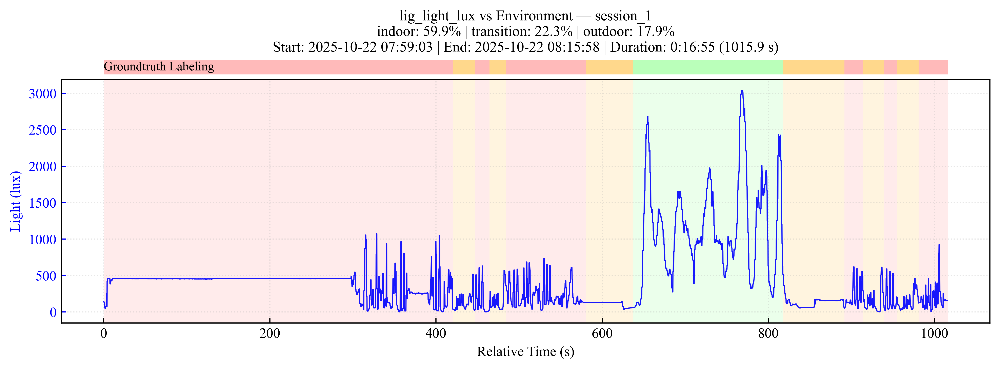

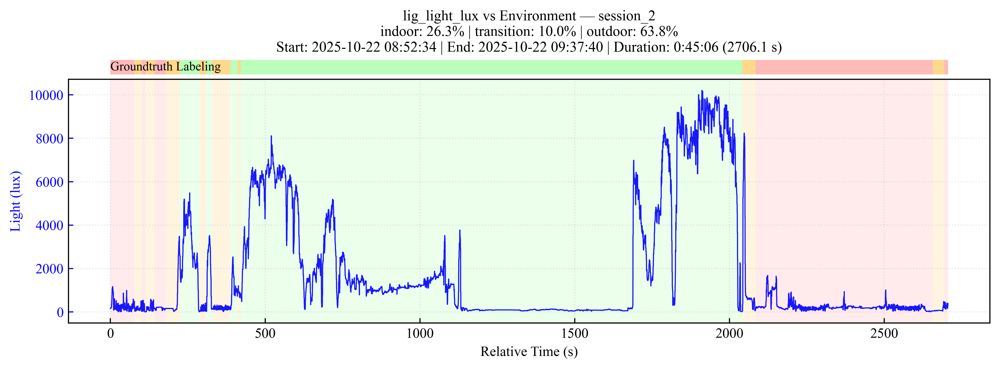

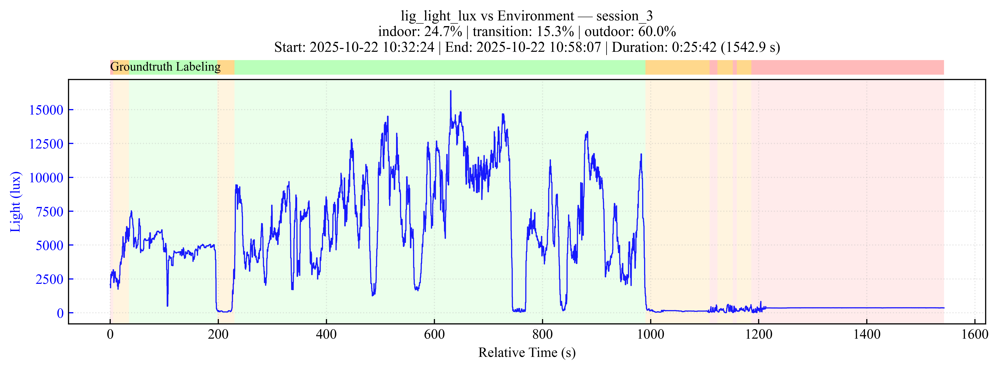

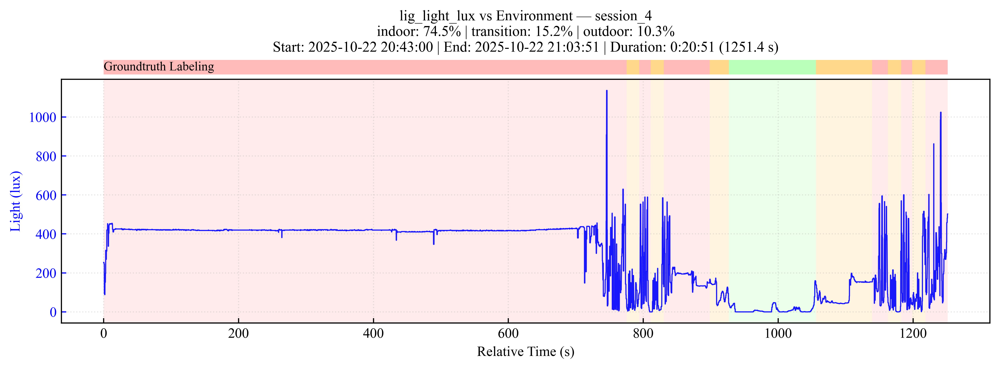

In [67]:
# Light sensor
plot_sensor_vs_env(fused, "lig", "lig_light_lux", ylabel="Light (lux)", color="blue")

# Magnetic norm
# plot_sensor_vs_env(fused, "mag", "mag_mag_norm", ylabel="Magnetic Norm (µT)", color="purple")

# # Barometric pressure
# plot_sensor_vs_env(fused, "prs", "prs_pressure_hpa", ylabel="Pressure (hPa)", color="blue")

# # Sound RMS or peak
# plot_sensor_vs_env(fused, "aud", "aud_rms", ylabel="Sound RMS", color="darkgreen")
# plot_sensor_vs_env(fused, "aud", "aud_peak", ylabel="Sound Peak", color="teal")


# Cellular RSRP
# plot_sensor_vs_env(fused, "cell", "cell_rsrp", ylabel="RSRP (dBm)", color="crimson")


📘 Found 4 session(s) for wifi: ['session_1' 'session_2' 'session_3' 'session_4']


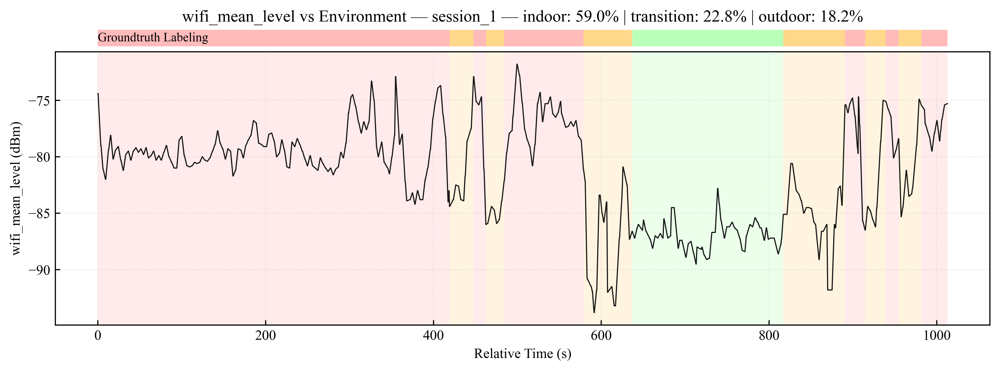

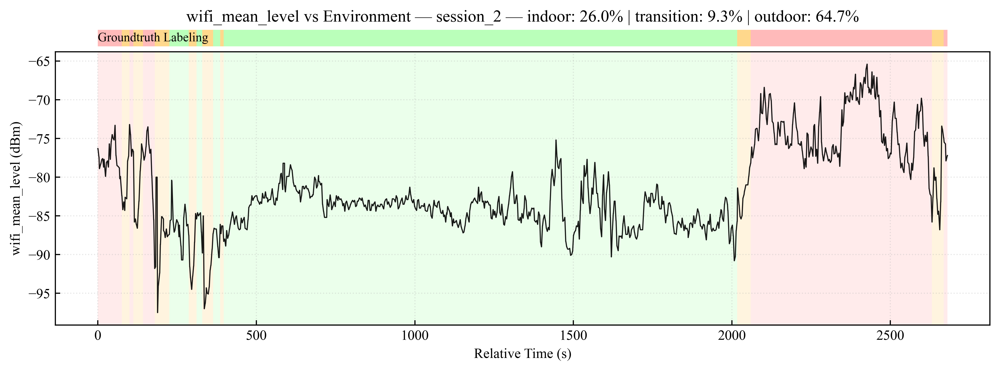

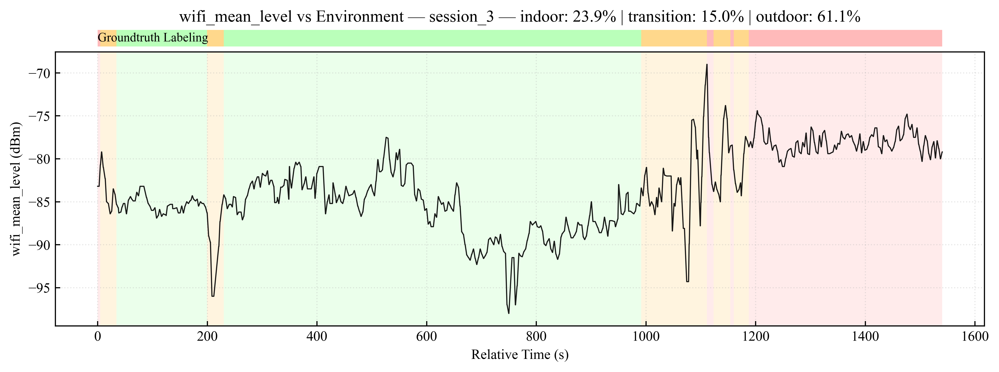

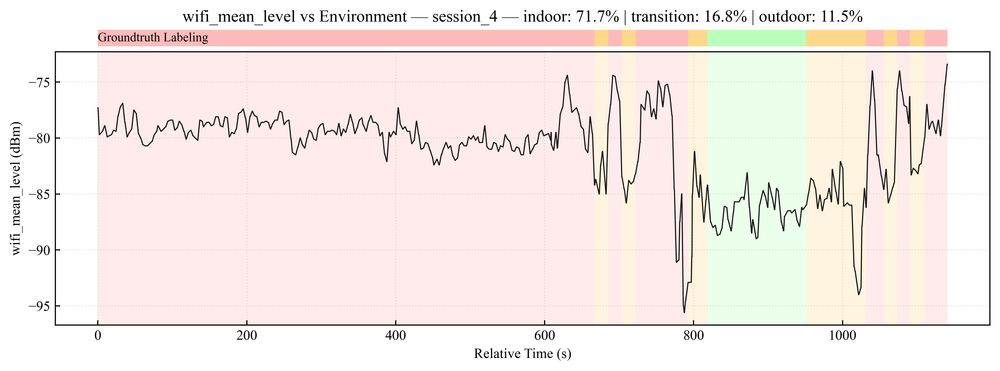

In [58]:
# WiFi strength
plot_sensor_vs_env(fused, "wifi", "wifi_mean_level", ylabel="wifi_mean_level (dBm)", color="black")


📘 Found 4 session(s) for wifi: ['session_1' 'session_2' 'session_3' 'session_4']


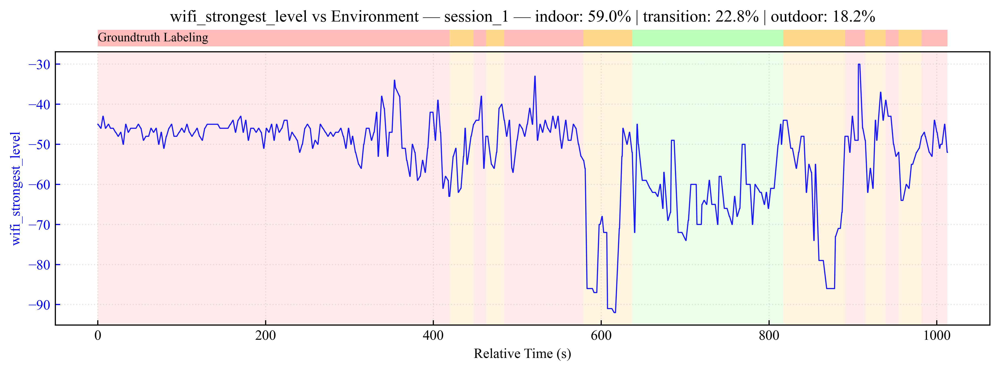

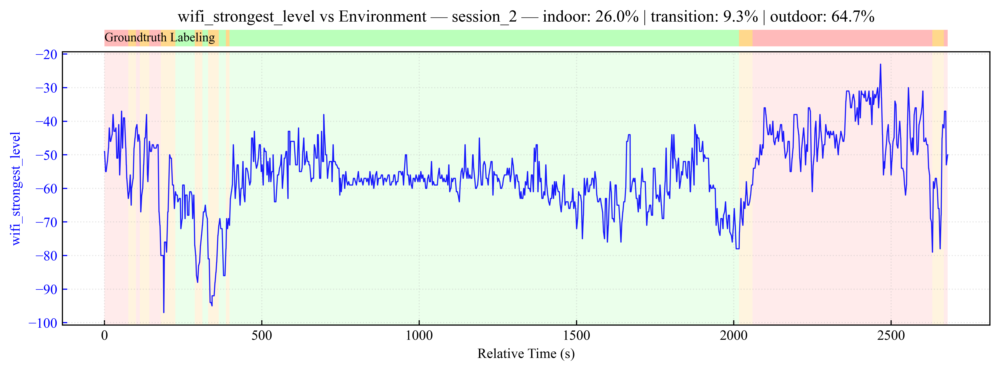

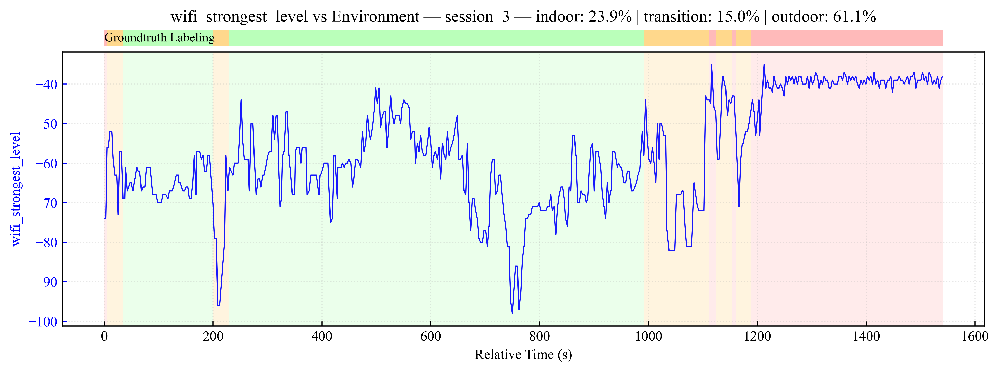

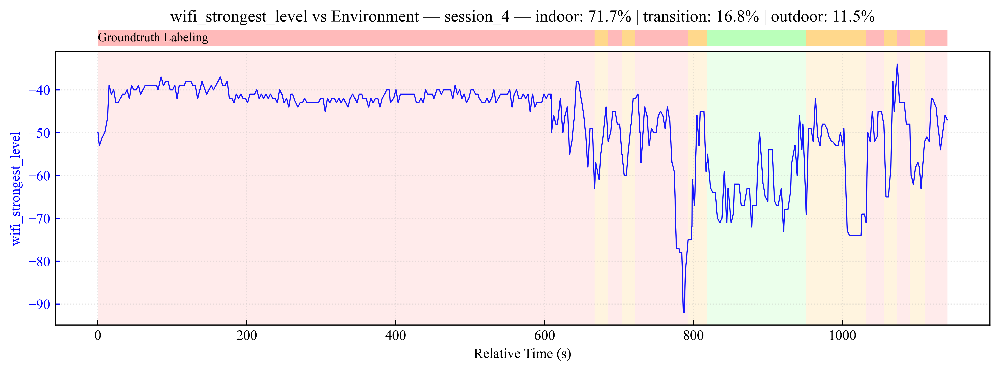

In [59]:
plot_sensor_vs_env(fused, "wifi", "wifi_strongest_level", ylabel="wifi_strongest_level", color="blue")


✅ Computed magnetic variance columns: ['mag_var', 'mag_var_smooth']
📘 Found 4 session(s) for mag: ['session_1' 'session_2' 'session_3' 'session_4']


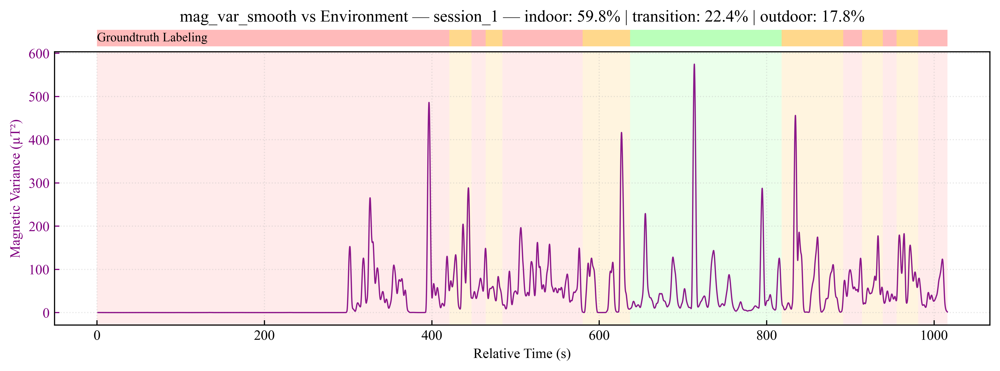

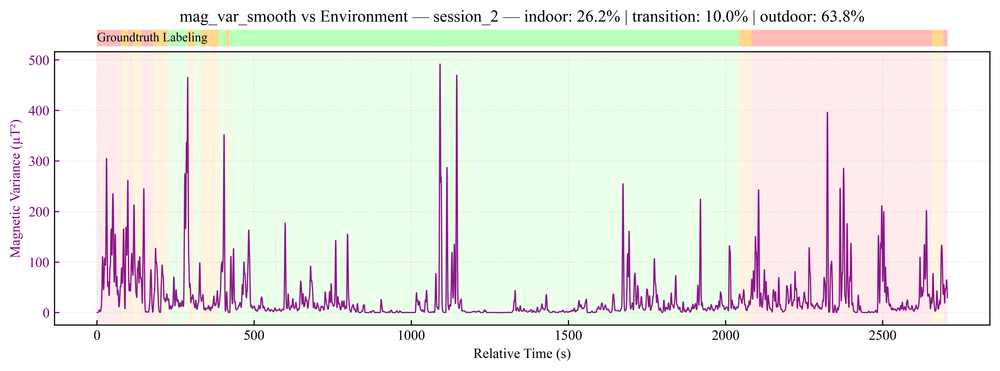

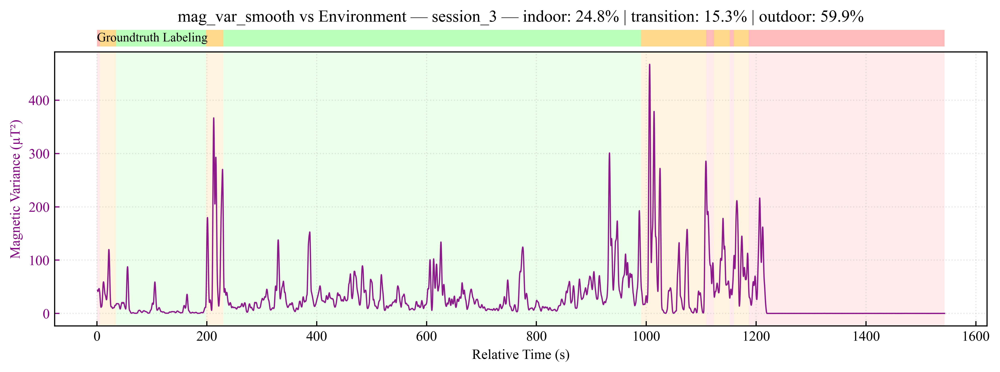

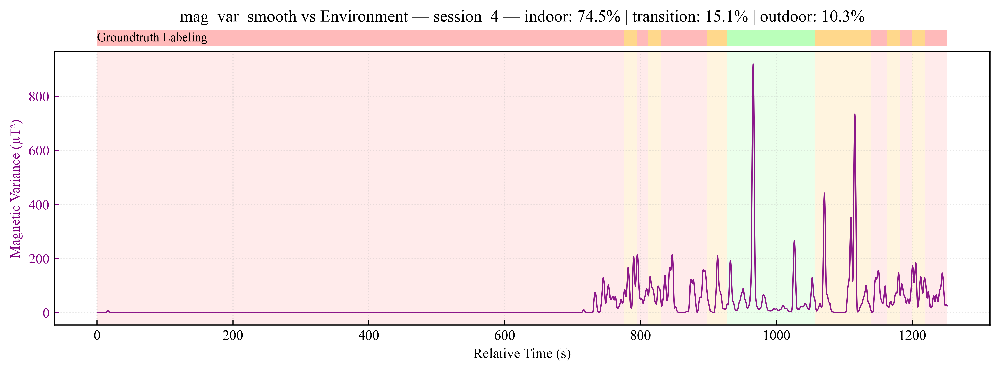

In [61]:
# ===============================================================
# 🧭 Magnetic Variance (Sliding Window) vs Environment
# ===============================================================

import numpy as np
import pandas as pd

# ---------------------------------------------------------------
# 1️⃣ Compute sliding variance of magnetic field
# ---------------------------------------------------------------
if not all(col in fused.columns for col in ["mag_mx", "mag_my", "mag_mz"]):
    raise KeyError("Missing magnetic columns: mag_mx, mag_my, mag_mz")

# Rolling window size (≈1.5s if 30–40Hz sampling)
window_size = 50  

# Variance of magnetic vector components
fused["mag_var"] = (
    fused[["mag_mx", "mag_my", "mag_mz"]]
    .rolling(window_size, min_periods=10)
    .var(ddof=0)
    .mean(axis=1)
)

# Optional smoothing
fused["mag_var_smooth"] = fused["mag_var"].rolling(20, min_periods=1).mean()

print("✅ Computed magnetic variance columns: ['mag_var', 'mag_var_smooth']")

# ---------------------------------------------------------------
# 2️⃣ Plot using your existing universal function
# ---------------------------------------------------------------
plot_sensor_vs_env(
    fused,
    sensor_prefix="mag",
    feature_col="mag_var_smooth",
    ylabel="Magnetic Variance (µT²)",
    color="purple",
    lw=0.9
)
